<a href="https://colab.research.google.com/github/shafi21001/fruit-freshness-edge-ai-study/blob/main/notebooks/04_validation_analysis_and_xai_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# GPU ACCESS TEST ONLY
# This does not train a model.

import torch
import platform

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("No GPU allocated.")

Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
GPU name: Tesla T4
GPU memory: 14.56 GB


In [3]:
# STEP 1 — Mount Google Drive and verify project access
# READ-ONLY: no training, no dataset modification, no test access.

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research"
)

print("=" * 65)
print("GOOGLE DRIVE / PROJECT ACCESS CHECK")
print("=" * 65)

print("Drive mounted:", Path("/content/drive/MyDrive").exists())
print("Expected project path:", PROJECT_ROOT)
print("Project folder accessible:", PROJECT_ROOT.exists())

if PROJECT_ROOT.exists():
    print("\nProject folder contents:")
    for item in sorted(PROJECT_ROOT.iterdir()):
        print(f"  {'[DIR]' if item.is_dir() else '[FILE]'} {item.name}")
else:
    print("\nSearching MyDrive for matching project folder...")
    matches = list(Path("/content/drive/MyDrive").glob("*Fruit*"))
    for item in matches:
        print("FOUND:", item)

print("\nTraining performed: NO")
print("Files modified: NO")
print("Test split accessed: NO")
print("=" * 65)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GOOGLE DRIVE / PROJECT ACCESS CHECK
Drive mounted: True
Expected project path: /content/drive/MyDrive/Fruit_Freshness_Research
Project folder accessible: True

Project folder contents:
  [DIR] datasets
  [DIR] documentation
  [DIR] experiments

Training performed: NO
Files modified: NO
Test split accessed: NO


In [4]:
# STEP 3 — Verify exact baseline training assets
# READ-ONLY: no training, no file modification, no test access.

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
EXP = ROOT / "experiments" / "baseline_mobilenetv3_small"
CACHE = ROOT / "datasets" / "cache" / "train_validation_cache"

required_files = [
    EXP / "train_baseline_v3.py",
    EXP / "resolved_training_config_v1.json",
    EXP / "unique_train_manifest.csv",
    EXP / "unique_validation_manifest.csv",
    EXP / "class_to_index.json",
]

print("=" * 70)
print("EXACT ASSET VERIFICATION")
print("=" * 70)

for p in required_files:
    status = "PASS" if p.exists() else "MISSING"
    size_mb = p.stat().st_size / (1024**2) if p.exists() else 0
    print(f"{status} | {p.name} | {size_mb:.3f} MB")

print("\n--- Manifest row counts ---")

for filename in ["unique_train_manifest.csv", "unique_validation_manifest.csv"]:
    p = EXP / filename
    if p.exists():
        df = pd.read_csv(p)
        print(f"{filename}: {len(df):,} rows")

print("\n--- Cache verification ---")

cache_images = CACHE / "images"
cache_manifest = CACHE / "train_validation_cache_manifest.csv"

print("Cache directory exists:", CACHE.exists())
print("Image directory exists:", cache_images.exists())
print("Cache manifest exists:", cache_manifest.exists())

if cache_images.exists():
    image_files = list(cache_images.glob("*.jpg"))
    print("Cached JPG images:", f"{len(image_files):,}")

if cache_manifest.exists():
    cache_df = pd.read_csv(cache_manifest)
    print("Cache manifest rows:", f"{len(cache_df):,}")

print("\nTraining performed: NO")
print("Files modified: NO")
print("Test split accessed: NO")
print("=" * 70)

EXACT ASSET VERIFICATION
PASS | train_baseline_v3.py | 0.025 MB
PASS | resolved_training_config_v1.json | 0.003 MB
PASS | unique_train_manifest.csv | 2.075 MB
PASS | unique_validation_manifest.csv | 0.450 MB
PASS | class_to_index.json | 0.001 MB

--- Manifest row counts ---
unique_train_manifest.csv: 3,401 rows
unique_validation_manifest.csv: 732 rows

--- Cache verification ---
Cache directory exists: True
Image directory exists: True
Cache manifest exists: True
Cached JPG images: 4,133
Cache manifest rows: 4,133

Training performed: NO
Files modified: NO
Test split accessed: NO


In [5]:
# STEP 4 — Read-only checkpoint persistence audit
# This inspects script text only. It does NOT execute the training script.

from pathlib import Path

script_path = EXP / "train_baseline_v3.py"
source = script_path.read_text(encoding="utf-8")
lines = source.splitlines()

keywords = [
    "BEST_CHECKPOINT",
    "LATEST_CHECKPOINT",
    "CHECKPOINT",
    "torch.save",
    "atomic",
    "save_checkpoint",
    "METRICS_CSV",
    "PER_CLASS_CSV",
    "RUN_STATUS_PATH",
]

print("=" * 75)
print("CHECKPOINT & PERSISTENCE SOURCE AUDIT")
print("=" * 75)

shown = set()

for keyword in keywords:
    matches = [i for i, line in enumerate(lines) if keyword in line]
    if matches:
        print(f"\n--- {keyword} | {len(matches)} match(es) ---")
        for i in matches[:8]:
            start = max(0, i - 2)
            end = min(len(lines), i + 4)
            for j in range(start, end):
                if j not in shown:
                    print(f"{j+1:04d}: {lines[j]}")
                    shown.add(j)
            print("...")

print("\n" + "=" * 75)
print("Inspection only.")
print("Training launched: NO")
print("Files modified: NO")
print("Test split accessed: NO")
print("=" * 75)

CHECKPOINT & PERSISTENCE SOURCE AUDIT

--- BEST_CHECKPOINT | 4 match(es) ---
0055: LOG_DIR = EXPERIMENT_DIR / "logs"
0056: 
0057: BEST_CHECKPOINT = CHECKPOINT_DIR / "best_validation_macro_f1.pt"
0058: LATEST_CHECKPOINT = CHECKPOINT_DIR / "latest_checkpoint.pt"
0059: METRICS_CSV = LOG_DIR / "training_metrics.csv"
0060: PER_CLASS_CSV = LOG_DIR / "per_class_metrics.csv"
...
0389:     # --------------------------------------------------------
0390:     existing_artifacts = [
0391:         BEST_CHECKPOINT,
0392:         LATEST_CHECKPOINT,
0393:         METRICS_CSV,
0394:         PER_CLASS_CSV,
...
0753:             atomic_save_checkpoint(
0754:                 best_payload,
0755:                 BEST_CHECKPOINT,
0756:             )
0757:         else:
0758:             epochs_without_improvement += 1
...
0832:     print(f"Final run status: {final_status}")
0833:     print(f"Run status file: {RUN_STATUS_PATH}")
0834:     print(f"Best checkpoint: {BEST_CHECKPOINT}")
0835:     print(f"Latest c

In [6]:
# STEP 5 — Verify persistent Drive checkpoint locations
# READ-ONLY. No training or file modification.

from pathlib import Path

script_path = EXP / "train_baseline_v3.py"
lines = script_path.read_text(encoding="utf-8").splitlines()

print("=" * 70)
print("EXPERIMENT AND CHECKPOINT PATH VERIFICATION")
print("=" * 70)

for i, line in enumerate(lines):
    if any(term in line for term in [
        "EXPERIMENT_DIR =",
        "CHECKPOINT_DIR =",
        "LOG_DIR =",
        "BEST_CHECKPOINT =",
        "LATEST_CHECKPOINT =",
        "CONFUSION_MATRIX_DIR =",
    ]):
        print(f"{i+1:04d}: {line.strip()}")

print("\n--- Expected Drive persistence ---")
print("Project root:", ROOT)
print("Experiment folder:", EXP)
print("On Google Drive:", str(EXP).startswith("/content/drive/"))

print("\n--- Checkpoint directory status ---")
checkpoint_dir = EXP / "checkpoints"
print("Checkpoint directory:", checkpoint_dir)
print("Currently exists:", checkpoint_dir.exists())

print("\n--- Logging directory status ---")
log_dir = EXP / "logs"
print("Log directory:", log_dir)
print("Currently exists:", log_dir.exists())

print("\nRead-only inspection: PASS")
print("Training launched: NO")
print("Files modified: NO")
print("Test split accessed: NO")
print("=" * 70)

EXPERIMENT AND CHECKPOINT PATH VERIFICATION
0044: EXPERIMENT_DIR = PROJECT_ROOT / "experiments" / "baseline_mobilenetv3_small"
0054: CHECKPOINT_DIR = EXPERIMENT_DIR / "checkpoints"
0055: LOG_DIR = EXPERIMENT_DIR / "logs"
0057: BEST_CHECKPOINT = CHECKPOINT_DIR / "best_validation_macro_f1.pt"
0058: LATEST_CHECKPOINT = CHECKPOINT_DIR / "latest_checkpoint.pt"
0062: CONFUSION_MATRIX_DIR = LOG_DIR / "validation_confusion_matrices"

--- Expected Drive persistence ---
Project root: /content/drive/MyDrive/Fruit_Freshness_Research
Experiment folder: /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small
On Google Drive: True

--- Checkpoint directory status ---
Checkpoint directory: /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/checkpoints
Currently exists: True

--- Logging directory status ---
Log directory: /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/logs
Currently exists: True


In [8]:
# STEP 6 — Test Drive write/read access
# Creates and removes only two temporary probe files.

from pathlib import Path
import uuid

directories = {
    "Checkpoint directory": EXP / "checkpoints",
    "Log directory": EXP / "logs",
}

print("=" * 70)
print("GOOGLE DRIVE WRITE/READ TEST")
print("=" * 70)

all_passed = True

for label, directory in directories.items():
    probe = directory / f".drive_access_probe_{uuid.uuid4().hex}.tmp"
    test_content = "Fruit-freshness Drive persistence test"

    try:
        directory.mkdir(parents=True, exist_ok=True)
        probe.write_text(test_content, encoding="utf-8")

        read_back = probe.read_text(encoding="utf-8")

        if read_back == test_content:
            print(f"PASS | {label}: write and read successful")
        else:
            print(f"FAIL | {label}: content mismatch")
            all_passed = False

    except Exception as exc:
        print(f"FAIL | {label}: {type(exc).__name__}: {exc}")
        all_passed = False

    finally:
        if probe.exists():
            try:
                probe.unlink()
                print(f"      Temporary probe removed: {not probe.exists()}")
            except Exception as exc:
                print(f"WARNING | Could not remove probe: {exc}")
                all_passed = False

print("\nOVERALL:", "PASS" if all_passed else "FAIL")
print("Model training performed: NO")
print("Existing experiment files modified: NO")
print("Test split accessed: NO")
print("=" * 70)

GOOGLE DRIVE WRITE/READ TEST
PASS | Checkpoint directory: write and read successful
      Temporary probe removed: True
PASS | Log directory: write and read successful
      Temporary probe removed: True

OVERALL: PASS
Model training performed: NO
Existing experiment files modified: NO
Test split accessed: NO


In [9]:
# STEP 7 — REAL PYTORCH CHECKPOINT PERSISTENCE TEST
# Safe dummy test: save -> reload -> verify -> remove
# Does NOT train the fruit model.

import torch
import uuid
from pathlib import Path

test_path = EXP / "checkpoints" / f"persistence_test_{uuid.uuid4().hex}.pt"

# Tiny dummy model (not our fruit classifier)
dummy_model = torch.nn.Linear(3, 2)
original_state = dummy_model.state_dict()

test_payload = {
    "test_marker": "fruit_freshness_checkpoint_test",
    "epoch": 123,
    "model_state": original_state,
    "test_tensor": torch.tensor([1.0, 2.0, 3.0]),
}

print("=" * 70)
print("PYTORCH CHECKPOINT PERSISTENCE TEST")
print("=" * 70)

try:
    # Save to Drive
    torch.save(test_payload, test_path)
    print("PASS | Checkpoint saved to Drive")
    print("File size:", f"{test_path.stat().st_size:,} bytes")

    # Reload from Drive
    loaded = torch.load(test_path, map_location="cpu", weights_only=False)
    print("PASS | Checkpoint reloaded")

    # Verify content
    assert loaded["test_marker"] == test_payload["test_marker"]
    assert loaded["epoch"] == 123
    assert torch.equal(loaded["test_tensor"], test_payload["test_tensor"])

    # Verify model weights
    for key in original_state:
        assert torch.equal(
            loaded["model_state"][key],
            original_state[key]
        )

    print("PASS | Content and model weights verified")

except Exception as exc:
    print("FAIL |", type(exc).__name__, str(exc))

finally:
    if test_path.exists():
        test_path.unlink()
        print("Temporary checkpoint removed:", not test_path.exists())

print("\nDummy checkpoint test only.")
print("Fruit model training: NO")
print("Existing checkpoints overwritten: NO")
print("Test split accessed: NO")
print("=" * 70)

PYTORCH CHECKPOINT PERSISTENCE TEST
PASS | Checkpoint saved to Drive
File size: 2,779 bytes
PASS | Checkpoint reloaded
PASS | Content and model weights verified
Temporary checkpoint removed: True

Dummy checkpoint test only.
Fruit model training: NO
Existing checkpoints overwritten: NO
Test split accessed: NO


In [10]:
from pathlib import Path
import ast
import json

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
EXP = ROOT / "experiments" / "baseline_mobilenetv3_small"

SCRIPT = EXP / "train_baseline_v3.py"
CONFIG = EXP / "resolved_training_config_v1.json"
CHECKPOINT_DIR = EXP / "checkpoints"
LOG_DIR = EXP / "logs"

print("=" * 65)
print("FINAL TRAINING LAUNCH-SAFETY CHECK")
print("=" * 65)

# 1. Verify required files
assert SCRIPT.exists(), f"Training script missing: {SCRIPT}"
assert CONFIG.exists(), f"Frozen config missing: {CONFIG}"

print("PASS | Training script exists")
print("PASS | Frozen configuration exists")

# 2. Check Python syntax without executing training
source = SCRIPT.read_text()
ast.parse(source)
print("PASS | V3 script syntax valid")

# 3. Verify frozen config can be read
config = json.loads(CONFIG.read_text())
print("PASS | Frozen config readable")

# 4. Check checkpoint and log directories
assert CHECKPOINT_DIR.exists(), "Checkpoint directory missing"
assert LOG_DIR.exists(), "Log directory missing"

checkpoint_files = list(CHECKPOINT_DIR.iterdir())
log_files = list(LOG_DIR.iterdir())

print(f"Checkpoint directory contents: {len(checkpoint_files)}")
print(f"Log directory contents: {len(log_files)}")

# 5. Do not overwrite any existing experiment artifacts
if checkpoint_files or log_files:
    print("STOP | Existing checkpoint/log artifacts detected")
    print("Do NOT launch a fresh training run.")
    print("Inspect these files first.")
else:
    print("PASS | Output directories are clean for a fresh run")

print("=" * 65)
print("SAFETY CHECK COMPLETE")
print("=" * 65)

FINAL TRAINING LAUNCH-SAFETY CHECK
PASS | Training script exists
PASS | Frozen configuration exists
PASS | V3 script syntax valid
PASS | Frozen config readable
Checkpoint directory contents: 2
Log directory contents: 3
STOP | Existing checkpoint/log artifacts detected
Do NOT launch a fresh training run.
Inspect these files first.
SAFETY CHECK COMPLETE


In [11]:
from pathlib import Path
from datetime import datetime
import json

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
EXP = ROOT / "experiments" / "baseline_mobilenetv3_small"

CHECKPOINT_DIR = EXP / "checkpoints"
LOG_DIR = EXP / "logs"

print("=" * 70)
print("EXISTING EXPERIMENT ARTIFACT INSPECTION")
print("=" * 70)

def inspect_directory(directory):
    print(f"\nDIRECTORY: {directory.name}")
    files = sorted(directory.iterdir())

    if not files:
        print("  Empty")
        return

    for path in files:
        if path.is_file():
            size_kb = path.stat().st_size / 1024
            modified = datetime.fromtimestamp(
                path.stat().st_mtime
            ).strftime("%Y-%m-%d %H:%M:%S")

            print(f"\n  Name: {path.name}")
            print(f"  Size: {size_kb:.2f} KB")
            print(f"  Modified: {modified}")
        else:
            print(f"\n  Directory: {path.name}")

inspect_directory(CHECKPOINT_DIR)
inspect_directory(LOG_DIR)

# Read run-status metadata only if present
print("\n" + "-" * 70)
print("RUN STATUS METADATA")
print("-" * 70)

for status_file in sorted(EXP.glob("run_status*.json")):
    print(f"\nFile: {status_file.name}")
    try:
        status = json.loads(status_file.read_text())
        print(json.dumps(status, indent=2))
    except Exception as error:
        print(f"Could not read status JSON: {error}")

print("\n" + "=" * 70)
print("INSPECTION ONLY — NO FILES MODIFIED")
print("No checkpoint weights loaded.")
print("No training performed.")
print("Test split not accessed.")
print("=" * 70)

EXISTING EXPERIMENT ARTIFACT INSPECTION

DIRECTORY: checkpoints

  Name: best_validation_macro_f1.pt
  Size: 6145.12 KB
  Modified: 2026-11-24 08:49:56

  Name: latest_checkpoint.pt
  Size: 18320.77 KB
  Modified: 2026-11-24 08:59:21

DIRECTORY: logs

  Name: per_class_metrics.csv
  Size: 9.90 KB
  Modified: 2026-11-24 08:59:18

  Name: training_metrics.csv
  Size: 1.76 KB
  Modified: 2026-11-24 08:59:18

  Directory: validation_confusion_matrices

----------------------------------------------------------------------
RUN STATUS METADATA
----------------------------------------------------------------------

File: run_status_v3.json
{
  "experiment_id": "baseline_mobilenetv3_small",
  "script_version": "v3",
  "status": "FAILED",
  "updated_at_utc": "2026-11-24T10:42:18.518204+00:00",
  "error_type": "RuntimeError",
  "error_message": "Existing experiment artifacts detected. Fresh training is blocked to prevent accidental overwrite. Use --resume only if a valid V2 latest checkpoint exi

In [12]:
from pathlib import Path
import torch

EXP = Path("/content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small")

latest_path = EXP / "checkpoints" / "latest_checkpoint.pt"
best_path = EXP / "checkpoints" / "best_validation_macro_f1.pt"

print("=" * 65)
print("CHECKPOINT RESUMABILITY INSPECTION")
print("=" * 65)

for path in [latest_path, best_path]:
    print(f"\nInspecting: {path.name}")

    if not path.exists():
        print("FAIL | File missing")
        continue

    try:
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        print("PASS | Checkpoint can be loaded")
        print("Checkpoint type:", type(checkpoint).__name__)

        if isinstance(checkpoint, dict):
            print("Keys:", list(checkpoint.keys()))

            for key in [
                "script_version",
                "completed_epoch",
                "epoch",
                "best_validation_macro_f1",
                "best_val_macro_f1",
                "patience_counter",
            ]:
                if key in checkpoint:
                    print(f"{key}: {checkpoint[key]}")

            for key in ["history", "metrics_history"]:
                if key in checkpoint:
                    value = checkpoint[key]
                    print(f"{key} type: {type(value).__name__}")
                    if isinstance(value, (list, dict)):
                        print(f"{key} length: {len(value)}")

            print("Resume-related fields:")
            for key in [
                "optimizer_state_dict",
                "scheduler_state_dict",
                "rng_state",
                "cuda_rng_state",
                "model_state_dict",
            ]:
                print(f"  {key}: {'PRESENT' if key in checkpoint else 'MISSING'}")

    except Exception as e:
        print("FAIL | Checkpoint load error:", repr(e))

print("\n" + "=" * 65)
print("INSPECTION ONLY — NO TRAINING OR FILE MODIFICATION")
print("Test split remains untouched.")
print("=" * 65)

CHECKPOINT RESUMABILITY INSPECTION

Inspecting: latest_checkpoint.pt
PASS | Checkpoint can be loaded
Checkpoint type: dict
Keys: ['completed_epoch', 'model_state', 'optimizer_state', 'best_macro_f1', 'epochs_without_improvement', 'history', 'per_class_history', 'python_rng_state', 'numpy_rng_state', 'torch_rng_state', 'loader_generator_state', 'cuda_rng_state_all', 'config_path', 'seed', 'script_version']
script_version: v3
completed_epoch: 7
history type: list
history length: 7
Resume-related fields:
  optimizer_state_dict: MISSING
  scheduler_state_dict: MISSING
  rng_state: MISSING
  cuda_rng_state: MISSING
  model_state_dict: MISSING

Inspecting: best_validation_macro_f1.pt
PASS | Checkpoint can be loaded
Checkpoint type: dict
Keys: ['completed_epoch', 'model_state', 'best_macro_f1', 'config_path', 'seed']
completed_epoch: 6
Resume-related fields:
  optimizer_state_dict: MISSING
  scheduler_state_dict: MISSING
  rng_state: MISSING
  cuda_rng_state: MISSING
  model_state_dict: MISSI

In [13]:
from pathlib import Path

script_path = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "experiments/baseline_mobilenetv3_small/train_baseline_v3.py"
)

lines = script_path.read_text().splitlines()

keywords = [
    "resume",
    "completed_epoch",
    "model_state",
    "optimizer_state",
    "python_rng_state",
    "numpy_rng_state",
    "torch_rng_state",
    "loader_generator_state",
    "cuda_rng_state_all",
]

matching_lines = set()

for i, line in enumerate(lines):
    if any(keyword in line for keyword in keywords):
        # Show context around each match
        start = max(0, i - 3)
        end = min(len(lines), i + 5)
        matching_lines.update(range(start, end))

print("=" * 70)
print("V3 RESUME-CODE COMPATIBILITY INSPECTION")
print("=" * 70)

previous = -2

for i in sorted(matching_lines):
    if i > previous + 1:
        print("\n...")
    print(f"{i+1:4d}: {lines[i]}")
    previous = i

print("\n" + "=" * 70)
print("READ-ONLY SCRIPT INSPECTION COMPLETE")
print("No training performed. No files modified. Test split untouched.")
print("=" * 70)

V3 RESUME-CODE COMPATIBILITY INSPECTION

...
   6: # IMPORTANT:
   7: # - Train and validation only.
   8: # - Test split is never loaded by this script.
   9: # - Supports resume from latest checkpoint.
  10: # - This script is not automatically launched when created.
  11: # ============================================================
  12: 
  13: from pathlib import Path

...
  84: # ------------------------------------------------------------
  85: def capture_rng_state(generator):
  86:     state = {
  87:         "python_rng_state": random.getstate(),
  88:         "numpy_rng_state": np.random.get_state(),
  89:         "torch_rng_state": torch.get_rng_state(),
  90:         "loader_generator_state": generator.get_state(),
  91:     }
  92: 
  93:     if torch.cuda.is_available():
  94:         state["cuda_rng_state_all"] = torch.cuda.get_rng_state_all()
  95: 
  96:     return state
  97: 
  98: 
  99: def restore_rng_state(checkpoint, generator):
 100:     required = [
 101:   

In [15]:
from pathlib import Path
import torch
import json

EXP = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "experiments/baseline_mobilenetv3_small"
)

checkpoint_path = EXP / "checkpoints" / "latest_checkpoint.pt"
config_path = EXP / "resolved_training_config_v1.json"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

config = json.loads(config_path.read_text())

print("=" * 65)
print("V3 RESUME GUARD VALIDATION")
print("=" * 65)

required_fields = [
    "model_state",
    "optimizer_state",
    "completed_epoch",
    "best_macro_f1",
    "epochs_without_improvement",
    "history",
    "per_class_history",
    "python_rng_state",
    "numpy_rng_state",
    "torch_rng_state",
    "loader_generator_state",
]

missing = [key for key in required_fields if key not in checkpoint]

assert not missing, f"Missing required fields: {missing}"
print("PASS | All required checkpoint fields present")

assert checkpoint.get("script_version") == "v3"
print("PASS | Script version is V3")

completed_epoch = int(checkpoint["completed_epoch"])
max_epochs = int(config["training"]["max_epochs"])
patience = int(config["training"]["early_stopping_patience"])
epochs_without_improvement = int(
    checkpoint["epochs_without_improvement"]
)

assert completed_epoch >= 1
assert completed_epoch < max_epochs
print(f"PASS | Epoch {completed_epoch} is below maximum {max_epochs}")

assert epochs_without_improvement < patience
print(
    f"PASS | Early-stopping counter "
    f"{epochs_without_improvement} is below patience {patience}"
)

history_epochs = [
    int(row["epoch"]) for row in checkpoint["history"]
]

expected_epochs = list(range(1, completed_epoch + 1))

assert history_epochs == expected_epochs, (
    f"History mismatch: {history_epochs}"
)

print("PASS | Training history matches completed epochs")

print("\nResume validation passed.")
print("No training performed.")
print("No files modified.")
print("Test split not accessed.")
print("=" * 65)

V3 RESUME GUARD VALIDATION
PASS | All required checkpoint fields present
PASS | Script version is V3
PASS | Epoch 7 is below maximum 15
PASS | Early-stopping counter 1 is below patience 3
PASS | Training history matches completed epochs

Resume validation passed.
No training performed.
No files modified.
Test split not accessed.


In [17]:
from pathlib import Path
import subprocess
import sys

EXP = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "experiments/baseline_mobilenetv3_small"
)

SCRIPT = EXP / "train_baseline_v3.py"

print("=" * 65)
print("RESUMING BASELINE MOBILENETV3-SMALL TRAINING")
print("=" * 65)
print("Resume checkpoint: latest_checkpoint.pt")
print("Expected starting epoch: 8")
print("Maximum configured epoch: 15")
print("Test split: NOT USED")
print("=" * 65)

result = subprocess.run(
    [sys.executable, str(SCRIPT), "--resume"],
    cwd=str(EXP)
)

print("\nTraining process exit code:", result.returncode)

if result.returncode == 0:
    print("Training process completed.")
else:
    print("Training process stopped or failed.")
    print("Preserve all existing checkpoints and logs.")

RESUMING BASELINE MOBILENETV3-SMALL TRAINING
Resume checkpoint: latest_checkpoint.pt
Expected starting epoch: 8
Maximum configured epoch: 15
Test split: NOT USED

Training process exit code: 1
Training process stopped or failed.
Preserve all existing checkpoints and logs.


In [18]:
from pathlib import Path
import json
import torch

EXP = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "experiments/baseline_mobilenetv3_small"
)

status_path = EXP / "run_status_v3.json"
latest_path = EXP / "checkpoints" / "latest_checkpoint.pt"

print("=" * 65)
print("RESUME FAILURE DIAGNOSTICS")
print("=" * 65)

# Read failure status
if status_path.exists():
    print("\n--- Run status ---")
    try:
        status = json.loads(status_path.read_text())
        print(json.dumps(status, indent=2))
    except Exception as e:
        print("Status read error:", repr(e))
else:
    print("Run status file not found.")

# Verify checkpoint remains present and readable
print("\n--- Latest checkpoint ---")
if latest_path.exists():
    print("File exists:", True)
    print("Size (MB):", round(latest_path.stat().st_size / (1024**2), 2))

    try:
        ckpt = torch.load(
            latest_path,
            map_location="cpu",
            weights_only=False
        )
        print("Load: PASS")
        print("Completed epoch:", ckpt.get("completed_epoch"))
        print("Script version:", ckpt.get("script_version"))
        print("History entries:", len(ckpt.get("history", [])))
    except Exception as e:
        print("Checkpoint load FAILED:", repr(e))
else:
    print("Latest checkpoint is MISSING!")

print("\n" + "=" * 65)
print("READ-ONLY DIAGNOSTICS")
print("No training launched. No files modified. Test split untouched.")
print("=" * 65)

RESUME FAILURE DIAGNOSTICS

--- Run status ---
{
  "experiment_id": "baseline_mobilenetv3_small",
  "script_version": "v3",
  "status": "FAILED",
  "updated_at_utc": "2026-11-24T10:50:51.251357+00:00",
  "error_type": "TypeError",
  "error_message": "RNG state must be a torch.ByteTensor"
}

--- Latest checkpoint ---
File exists: True
Size (MB): 17.89
Load: PASS
Completed epoch: 7
Script version: v3
History entries: 7

READ-ONLY DIAGNOSTICS
No training launched. No files modified. Test split untouched.


In [19]:
from pathlib import Path
import torch

EXP = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "experiments/baseline_mobilenetv3_small"
)

ckpt_path = EXP / "checkpoints" / "latest_checkpoint.pt"
ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)

print("=" * 65)
print("RNG STATE TYPE DIAGNOSTIC")
print("=" * 65)

rng_keys = [
    "python_rng_state",
    "numpy_rng_state",
    "torch_rng_state",
    "loader_generator_state",
    "cuda_rng_state_all",
]

for key in rng_keys:
    if key not in ckpt:
        print(f"{key}: MISSING")
        continue

    value = ckpt[key]
    print(f"\n{key}:")
    print("  Python type:", type(value))

    if isinstance(value, torch.Tensor):
        print("  Tensor dtype:", value.dtype)
        print("  Tensor shape:", tuple(value.shape))
    elif isinstance(value, (list, tuple)):
        print("  Container length:", len(value))
        if len(value) > 0:
            print("  First element type:", type(value[0]))
            if isinstance(value[0], torch.Tensor):
                print("  First element dtype:", value[0].dtype)
                print("  First element shape:", tuple(value[0].shape))

print("\n--- PyTorch RNG restoration requirements ---")
print("torch.set_rng_state requires a ByteTensor RNG state.")
print("This diagnostic does not attempt to restore any RNG state.")

print("\n" + "=" * 65)
print("READ-ONLY | Checkpoint untouched | No training | Test split untouched")
print("=" * 65)

RNG STATE TYPE DIAGNOSTIC

python_rng_state:
  Python type: <class 'tuple'>
  Container length: 3
  First element type: <class 'int'>

numpy_rng_state:
  Python type: <class 'tuple'>
  Container length: 5
  First element type: <class 'str'>

torch_rng_state:
  Python type: <class 'torch.Tensor'>
  Tensor dtype: torch.uint8
  Tensor shape: (5056,)

loader_generator_state:
  Python type: <class 'torch.Tensor'>
  Tensor dtype: torch.uint8
  Tensor shape: (5056,)

cuda_rng_state_all:
  Python type: <class 'list'>
  Container length: 1
  First element type: <class 'torch.Tensor'>
  First element dtype: torch.uint8
  First element shape: (16,)

--- PyTorch RNG restoration requirements ---
torch.set_rng_state requires a ByteTensor RNG state.
This diagnostic does not attempt to restore any RNG state.

READ-ONLY | Checkpoint untouched | No training | Test split untouched


In [20]:
from pathlib import Path
import torch

EXP = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "experiments/baseline_mobilenetv3_small"
)

script = (EXP / "train_baseline_v3.py").read_text().splitlines()

print("=" * 65)
print("EXACT RNG RESTORE CODE")
print("=" * 65)

for start, end in [(80, 125), (540, 680), (830, 865)]:
    print(f"\n--- Lines {start}-{end} ---")
    for i in range(start - 1, min(end, len(script))):
        print(f"{i+1:4}: {script[i]}")

print("\n--- Runtime ---")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("CUDA version:", torch.version.cuda)
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDiagnostic only: no RNG restoration, training, or file changes.")

EXACT RNG RESTORE CODE

--- Lines 80-125 ---
  80: 
  81: 
  82: # ------------------------------------------------------------
  83: # RNG state capture and restoration
  84: # ------------------------------------------------------------
  85: def capture_rng_state(generator):
  86:     state = {
  87:         "python_rng_state": random.getstate(),
  88:         "numpy_rng_state": np.random.get_state(),
  89:         "torch_rng_state": torch.get_rng_state(),
  90:         "loader_generator_state": generator.get_state(),
  91:     }
  92: 
  93:     if torch.cuda.is_available():
  94:         state["cuda_rng_state_all"] = torch.cuda.get_rng_state_all()
  95: 
  96:     return state
  97: 
  98: 
  99: def restore_rng_state(checkpoint, generator):
 100:     required = [
 101:         "python_rng_state",
 102:         "numpy_rng_state",
 103:         "torch_rng_state",
 104:         "loader_generator_state",
 105:     ]
 106: 
 107:     missing = [key for key in required if key not in ch

In [21]:
from pathlib import Path
import shutil
import ast
from datetime import datetime

EXP = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "experiments/baseline_mobilenetv3_small"
)

SCRIPT = EXP / "train_baseline_v3.py"

# Read original script
original = SCRIPT.read_text()

# Exact targeted change: checkpoint loaded on CPU
old = '''checkpoint = torch.load(
                LATEST_CHECKPOINT,
                map_location=device,
                weights_only=False,
            )'''

new = '''checkpoint = torch.load(
                LATEST_CHECKPOINT,
                map_location="cpu",
                weights_only=False,
            )'''

# Ensure we only patch the intended code once
count = original.count(old)
assert count == 1, (
    f"Expected exactly one matching resume-load block; found {count}. "
    "No changes made."
)

# Create timestamped backup
backup = EXP / f"train_baseline_v3_backup_before_rng_fix_{datetime.now().strftime('%Y%m%d_%H%M%S')}.py"
shutil.copy2(SCRIPT, backup)
print("Backup created:", backup.name)

# Apply patch
patched = original.replace(old, new, 1)

# Syntax validation before writing
ast.parse(patched)

# Write updated script
SCRIPT.write_text(patched)

# Read back and verify
updated = SCRIPT.read_text()
assert new in updated
ast.parse(updated)

print("\nPASS | Exact checkpoint-load location patched")
print("PASS | Python syntax valid")
print("PASS | Patched script verified after saving")

print("\n--- Changed resume-loading block ---")
lines = updated.splitlines()

for i, line in enumerate(lines):
    if "LATEST_CHECKPOINT," in line and i > 0:
        for j in range(max(0, i-2), min(len(lines), i+5)):
            print(f"{j+1:4}: {lines[j]}")
        break

print("\nBackup retained:", backup.exists())
print("Checkpoint files were NOT modified.")
print("Training was NOT launched.")
print("Test split was NOT accessed.")

Backup created: train_baseline_v3_backup_before_rng_fix_20261124_105355.py

PASS | Exact checkpoint-load location patched
PASS | Python syntax valid
PASS | Patched script verified after saving

--- Changed resume-loading block ---
 390:     existing_artifacts = [
 391:         BEST_CHECKPOINT,
 392:         LATEST_CHECKPOINT,
 393:         METRICS_CSV,
 394:         PER_CLASS_CSV,
 395:         RUN_STATUS_PATH,
 396:     ]

Backup retained: True
Checkpoint files were NOT modified.
Training was NOT launched.
Test split was NOT accessed.


In [22]:
from pathlib import Path

script = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "experiments/baseline_mobilenetv3_small/train_baseline_v3.py"
)

lines = script.read_text().splitlines()

print("=== Actual checkpoint loading block ===")
for i in range(550, 570):
    print(f"{i+1:4}: {lines[i]}")

print("\n=== All map_location occurrences ===")
for i, line in enumerate(lines):
    if "map_location=" in line:
        print(f"{i+1:4}: {line.strip()}")

=== Actual checkpoint loading block ===
 551:         if not LATEST_CHECKPOINT.exists():
 552:             raise FileNotFoundError(
 553:                 "Resume requested, but latest checkpoint is missing."
 554:             )
 555: 
 556:         try:
 557:             checkpoint = torch.load(
 558:                 LATEST_CHECKPOINT,
 559:                 map_location="cpu",
 560:                 weights_only=False,
 561:             )
 562:         except TypeError:
 563:             checkpoint = torch.load(
 564:                 LATEST_CHECKPOINT,
 565:                 map_location=device,
 566:             )
 567: 
 568:         # --------------------------------------------------------
 569:         # STRICT V3 CHECKPOINT VALIDATION
 570:         # --------------------------------------------------------

=== All map_location occurrences ===
 559: map_location="cpu",
 565: map_location=device,


In [23]:
from pathlib import Path
import ast

SCRIPT = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "experiments/baseline_mobilenetv3_small/train_baseline_v3.py"
)

source = SCRIPT.read_text()

old = '''        except TypeError:
            checkpoint = torch.load(
                LATEST_CHECKPOINT,
                map_location=device,
            )'''

new = '''        except TypeError:
            checkpoint = torch.load(
                LATEST_CHECKPOINT,
                map_location="cpu",
            )'''

assert source.count(old) == 1, (
    "Expected exactly one fallback block; no changes made."
)

updated = source.replace(old, new, 1)
ast.parse(updated)
SCRIPT.write_text(updated)

# Verify both loading paths
check = SCRIPT.read_text()
assert 'map_location="cpu"' in check
ast.parse(check)

print("PASS | Both checkpoint loading paths use CPU")
print("PASS | Script syntax valid")
print("PASS | Patch verified")
print("Training not launched")
print("Checkpoints unchanged")
print("Test split untouched")

PASS | Both checkpoint loading paths use CPU
PASS | Script syntax valid
PASS | Patch verified
Training not launched
Checkpoints unchanged
Test split untouched


In [24]:
from pathlib import Path
import subprocess
import sys

EXP = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "experiments/baseline_mobilenetv3_small"
)
SCRIPT = EXP / "train_baseline_v3.py"

print("=" * 65)
print("RESUMING TRAINING FROM EPOCH 7")
print("Next expected epoch: 8")
print("Test split: NOT USED")
print("=" * 65)

result = subprocess.run(
    [sys.executable, "-u", str(SCRIPT), "--resume"],
    cwd=str(EXP),
)

print("\nProcess exit code:", result.returncode)
print("=" * 65)

RESUMING TRAINING FROM EPOCH 7
Next expected epoch: 8
Test split: NOT USED

Process exit code: 0


In [25]:
import json
import pandas as pd
import torch
from pathlib import Path

EXP = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "experiments/baseline_mobilenetv3_small"
)

status_file = EXP / "run_status_v3.json"
metrics_file = EXP / "logs/training_metrics.csv"
latest_file = EXP / "checkpoints/latest_checkpoint.pt"
best_file = EXP / "checkpoints/best_validation_macro_f1.pt"

print("=" * 60)
print("1. RUN STATUS")
print("=" * 60)

if status_file.exists():
    status = json.loads(status_file.read_text())
    print(json.dumps(status, indent=2, default=str))
else:
    print("Status file missing")

print("\n" + "=" * 60)
print("2. TRAINING METRICS (LAST 5 ROWS)")
print("=" * 60)

if metrics_file.exists():
    df = pd.read_csv(metrics_file)
    print(df.tail(5).to_string(index=False))
    print(f"\nTotal recorded epochs: {len(df)}")
else:
    print("Metrics file missing")

print("\n" + "=" * 60)
print("3. LATEST CHECKPOINT")
print("=" * 60)

if latest_file.exists():
    ckpt = torch.load(latest_file, map_location="cpu", weights_only=False)
    print("Checkpoint epoch:", ckpt.get("completed_epoch"))
    print("History length:", len(ckpt.get("history", [])))
    print("Best validation Macro-F1:", ckpt.get("best_macro_f1"))
    print("Early stopping counter:", ckpt.get("epochs_without_improvement"))
else:
    print("Latest checkpoint missing")

print("\n" + "=" * 60)
print("4. BEST CHECKPOINT")
print("=" * 60)

if best_file.exists():
    best = torch.load(best_file, map_location="cpu", weights_only=False)
    print("Best checkpoint epoch:", best.get("completed_epoch"))
    print("Best validation Macro-F1:", best.get("best_macro_f1"))
else:
    print("Best checkpoint missing")

print("\nVerification complete. No files modified.")

1. RUN STATUS
{
  "experiment_id": "baseline_mobilenetv3_small",
  "script_version": "v3",
  "status": "EARLY_STOPPED",
  "updated_at_utc": "2026-11-24T12:46:03.661997+00:00",
  "completed_epoch": 14,
  "max_epochs": 15,
  "best_validation_macro_f1": 0.9181226945284862,
  "seed": 20261119,
  "device": "cuda",
  "config_path": "/content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/resolved_training_config_v1.json",
  "resume_requested": true
}

2. TRAINING METRICS (LAST 5 ROWS)
 epoch  train_loss  train_accuracy  train_macro_precision  train_macro_recall  train_macro_f1  train_weighted_f1  val_loss  val_accuracy  val_macro_precision  val_macro_recall  val_macro_f1  val_weighted_f1
    10    0.119371        0.958248               0.963660            0.962515        0.962801           0.958188  0.280857      0.905738             0.917968          0.914634      0.914152         0.905092
    11    0.109911        0.963834               0.968510            0.

In [26]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import sys
import importlib.metadata as metadata

import torch
import torchvision

# Experiment directory
EXP = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "experiments/baseline_mobilenetv3_small"
)

# Evidence output directory
EVIDENCE = EXP / "evidence"
EVIDENCE.mkdir(parents=True, exist_ok=True)

# Key experiment files to fingerprint
files_to_record = [
    EXP / "train_baseline_v3.py",
    EXP / "resolved_training_config_v1.json",
    EXP / "experiment_config.json",
    EXP / "class_to_index.json",
    EXP / "unique_train_manifest.csv",
    EXP / "unique_validation_manifest.csv",
    EXP / "checkpoints" / "best_validation_macro_f1.pt",
    EXP / "checkpoints" / "latest_checkpoint.pt",
    EXP / "logs" / "training_metrics.csv",
    EXP / "logs" / "per_class_metrics.csv",
    EXP / "run_status_v3.json",
]

# Include validation confusion-matrix evidence files
confusion_dir = EXP / "logs" / "validation_confusion_matrices"
if confusion_dir.exists():
    files_to_record.extend(
        p for p in confusion_dir.rglob("*") if p.is_file()
    )

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Record file fingerprints
file_records = []
missing_files = []

for path in files_to_record:
    if path.is_file():
        file_records.append({
            "relative_path": str(path.relative_to(EXP)),
            "size_bytes": path.stat().st_size,
            "sha256": sha256_file(path),
        })
    else:
        missing_files.append(str(path))

# Software environment
package_names = [
    "torch", "torchvision", "numpy", "pandas",
    "scikit-learn", "Pillow", "matplotlib"
]

packages = {}
for package in package_names:
    try:
        packages[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        packages[package] = "not installed"

gpu_info = {
    "cuda_available": torch.cuda.is_available(),
    "torch_cuda_version": torch.version.cuda,
    "device_count": torch.cuda.device_count(),
    "devices": [],
}

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(i)
        gpu_info["devices"].append({
            "index": i,
            "name": props.name,
            "total_memory_bytes": props.total_memory,
        })

manifest = {
    "manifest_created_utc": datetime.now(timezone.utc).isoformat(),
    "experiment_id": "baseline_mobilenetv3_small",
    "script_version": "v3",
    "purpose": "Baseline training reproducibility and artifact integrity record",
    "test_split_accessed": False,
    "environment": {
        "python_version": sys.version,
        "platform": platform.platform(),
        "pytorch_version": torch.__version__,
        "torchvision_version": torchvision.__version__,
        "packages": packages,
        "gpu": gpu_info,
    },
    "artifacts": file_records,
    "missing_expected_files": missing_files,
}

manifest_path = EVIDENCE / "baseline_evidence_manifest_v1.json"

manifest_path.write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

print("=" * 65)
print("BASELINE EVIDENCE MANIFEST")
print("=" * 65)
print("Manifest:", manifest_path)
print("Files fingerprinted:", len(file_records))
print("Missing expected files:", len(missing_files))
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if gpu_info["devices"]:
    for device in gpu_info["devices"]:
        print("GPU:", device["name"])

print("\nRecorded artifacts:")
for item in file_records:
    print(
        item["relative_path"],
        "| SHA-256:",
        item["sha256"][:16] + "..."
    )

if missing_files:
    print("\nMissing files:")
    for item in missing_files:
        print("-", item)

print("\nPASS | Evidence manifest written")
print("Test split accessed: NO")

BASELINE EVIDENCE MANIFEST
Manifest: /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/evidence/baseline_evidence_manifest_v1.json
Files fingerprinted: 25
Missing expected files: 0
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA available: True
GPU: Tesla T4

Recorded artifacts:
train_baseline_v3.py | SHA-256: 1eb5e112cc098395...
resolved_training_config_v1.json | SHA-256: 8ac85cd65667fa4e...
experiment_config.json | SHA-256: fefcf624b88e53b3...
class_to_index.json | SHA-256: 11584a7b264df4f4...
unique_train_manifest.csv | SHA-256: 4e9a8978e82bf8f5...
unique_validation_manifest.csv | SHA-256: 97840bff9a19b4c8...
checkpoints/best_validation_macro_f1.pt | SHA-256: 327f216c7b5f9115...
checkpoints/latest_checkpoint.pt | SHA-256: 4edcbf7b42288f4e...
logs/training_metrics.csv | SHA-256: 6dbf24babd6a426b...
logs/per_class_metrics.csv | SHA-256: 5eac1918c2dc01fa...
run_status_v3.json | SHA-256: 3aae099e60815c85...
logs/validation_confusion_matrices/val

In [27]:
import json
import hashlib
from pathlib import Path

EXP = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "experiments/baseline_mobilenetv3_small"
)

MANIFEST_PATH = (
    EXP / "evidence" / "baseline_evidence_manifest_v1.json"
)

manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

verified = 0
failed = []
missing = []

for item in manifest["artifacts"]:
    path = EXP / item["relative_path"]

    if not path.exists():
        missing.append(item["relative_path"])
        continue

    current_hash = sha256_file(path)

    if current_hash == item["sha256"]:
        verified += 1
    else:
        failed.append({
            "file": item["relative_path"],
            "expected": item["sha256"],
            "current": current_hash,
        })

print("=" * 60)
print("EVIDENCE MANIFEST INTEGRITY CHECK")
print("=" * 60)
print("Manifest entries:", len(manifest["artifacts"]))
print("Verified hashes:", verified)
print("Missing files:", len(missing))
print("Hash mismatches:", len(failed))

if missing:
    print("\nMISSING:")
    for p in missing:
        print("-", p)

if failed:
    print("\nMISMATCHES:")
    for item in failed:
        print("-", item["file"])

if not missing and not failed and verified == len(manifest["artifacts"]):
    print("\nPASS | All artifact hashes match the evidence manifest")
else:
    print("\nWARNING | Integrity verification requires investigation")

print("\nNo training performed.")
print("No evaluation performed.")
print("Test split not accessed.")

EVIDENCE MANIFEST INTEGRITY CHECK
Manifest entries: 25
Verified hashes: 25
Missing files: 0
Hash mismatches: 0

PASS | All artifact hashes match the evidence manifest

No training performed.
No evaluation performed.
Test split not accessed.


In [28]:
# STEP 3 — Read-only preparation for validation error analysis
# No training, inference, evaluation, or test-set access.

from pathlib import Path
import json
import torch

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
EXP = ROOT / "experiments" / "baseline_mobilenetv3_small"

files_to_check = {
    "Best checkpoint (Epoch 11)": EXP / "checkpoints" / "best_validation_macro_f1.pt",
    "Validation manifest": EXP / "unique_validation_manifest.csv",
    "Class mapping": EXP / "class_to_index.json",
    "Resolved training config": EXP / "resolved_training_config_v1.json",
    "Training metrics": EXP / "logs" / "training_metrics.csv",
    "Evidence manifest": EXP / "evidence" / "baseline_evidence_manifest_v1.json",
}

print("=" * 65)
print("VALIDATION ANALYSIS PREPARATION — READ-ONLY CHECK")
print("=" * 65)

all_present = True

for name, path in files_to_check.items():
    exists = path.exists()
    status = "PASS" if exists else "MISSING"
    print(f"{status} | {name}")
    if exists:
        print(f"       {path}")
    else:
        all_present = False

print("\n" + "-" * 65)

if all_present:
    # Read metadata only; do not load model weights into a model or run inference.
    checkpoint_path = files_to_check["Best checkpoint (Epoch 11)"]

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False
        )

        print("Checkpoint readable: PASS")
        print("Checkpoint keys:", list(checkpoint.keys()))

        if "completed_epoch" in checkpoint:
            print("Checkpoint epoch:", checkpoint["completed_epoch"])

        if "best_validation_macro_f1" in checkpoint:
            print("Best validation Macro-F1:",
                  checkpoint["best_validation_macro_f1"])

        # Read class mapping
        with open(files_to_check["Class mapping"], "r") as f:
            class_map = json.load(f)

        print("Number of classes:", len(class_map))
        print("Class mapping readable: PASS")

        print("\n" + "=" * 65)
        print("PREPARATION RESULT")
        print("=" * 65)
        print("PASS | Required files present and checkpoint readable")
        print("No training performed.")
        print("No inference performed.")
        print("No evaluation performed.")
        print("Test split not accessed.")

    except Exception as e:
        print("\nCHECK FAILED")
        print(type(e).__name__, str(e))

else:
    print("\nSTOP | One or more required files are missing.")
    print("No training, inference, or evaluation performed.")
    print("Test split not accessed.")

VALIDATION ANALYSIS PREPARATION — READ-ONLY CHECK
PASS | Best checkpoint (Epoch 11)
       /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/checkpoints/best_validation_macro_f1.pt
PASS | Validation manifest
       /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/unique_validation_manifest.csv
PASS | Class mapping
       /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/class_to_index.json
PASS | Resolved training config
       /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/resolved_training_config_v1.json
PASS | Training metrics
       /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/logs/training_metrics.csv
PASS | Evidence manifest
       /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/evidence/baseline_evidence_manifest_v1.json

----------------------------

In [29]:
# STEP 4A — Inspect validation manifest structure
# Read-only: no model inference, no training, no test access.

import pandas as pd
from pathlib import Path

EXP = Path("/content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small")
manifest_path = EXP / "unique_validation_manifest.csv"

df = pd.read_csv(manifest_path)

print("=" * 65)
print("VALIDATION MANIFEST INSPECTION")
print("=" * 65)

print("\nShape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\n" + "=" * 65)
print("INSPECTION COMPLETE")
print("=" * 65)
print("No inference performed.")
print("No training performed.")
print("Test split not accessed.")

VALIDATION MANIFEST INSPECTION

Shape: (732, 21)

Column names:
['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256', 'duplicate_group_id', 'duplicate_group_unique_hashes', 'quarantine_reason', 'dataset_status', 'group_requires_quarantine', 'split_group_id', 'split', 'final_group_type', 'final_dataset_status', 'final_quarantine_flag', 'final_grouping_method', 'metadata_reconciliation_note', 'class_name', 'cache_path']

First 5 rows:


,dataset,filename,relative_path,fruit,grade,file_size,sha256,duplicate_group_id,duplicate_group_unique_hashes,quarantine_reason,...,group_requires_quarantine,split_group_id,split,final_group_type,final_dataset_status,final_quarantine_flag,final_grouping_method,metadata_reconciliation_note,class_name,cache_path
0,AFruitDB,IMG_20230930_172415.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1150602,3d8522b532808676afab5a21758d7b662ec187dfdad52e...,SINGLETON,1,NaN,...,True,SHA_3d8522b532808676afab5a21758d7b662ec187dfda...,validation,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...,Apple_1st grade,/content/fruit_freshness_cache/images/3d8522b5...
1,AFruitDB,IMG_20230930_172456.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1184501,52d3a10d1026f1a09158006e0efc3b9b1e75f18fd346a9...,SINGLETON,1,NaN,...,True,SHA_52d3a10d1026f1a09158006e0efc3b9b1e75f18fd3...,validation,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...,Apple_1st grade,/content/fruit_freshness_cache/images/52d3a10d...
2,AFruitDB,IMG_20230930_172633.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1188568,c9597811abc4ac28bbe3ce50357f9b08238b0e54ea0fac...,SINGLETON,1,NaN,...,True,SHA_c9597811abc4ac28bbe3ce50357f9b08238b0e54ea...,validation,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...,Apple_1st grade,/content/fruit_freshness_cache/images/c9597811...
3,AFruitDB,IMG_20230930_172636.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1182612,0ccb44216486daadf93cb2cbfa27d56e3d099ecfebab92...,SINGLETON,1,NaN,...,True,SHA_0ccb44216486daadf93cb2cbfa27d56e3d099ecfeb...,validation,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...,Apple_1st grade,/content/fruit_freshness_cache/images/0ccb4421...
4,AFruitDB,IMG_20230930_172707.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1105279,ae90728b6aef9c246b0b122dae84242a6f6b233f280b12...,SINGLETON,1,NaN,...,True,SHA_ae90728b6aef9c246b0b122dae84242a6f6b233f28...,validation,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...,Apple_1st grade,/content/fruit_freshness_cache/images/ae90728b...



Data types:
dataset                           object
filename                          object
relative_path                     object
fruit                             object
grade                             object
file_size                          int64
sha256                            object
duplicate_group_id                object
duplicate_group_unique_hashes      int64
quarantine_reason                float64
dataset_status                    object
group_requires_quarantine           bool
split_group_id                    object
split                             object
final_group_type                  object
final_dataset_status              object
final_quarantine_flag               bool
final_grouping_method             object
metadata_reconciliation_note      object
class_name                        object
cache_path                        object
dtype: object

Missing values:
dataset                            0
filename                           0
relative_path        

In [30]:
# STEP 4B — Inspect model definition and preprocessing from the original script
# Read-only inspection. No training, inference, or test access.

from pathlib import Path

EXP = Path("/content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small")
script_path = EXP / "train_baseline_v3.py"

text = script_path.read_text(encoding="utf-8")

keywords = [
    "mobilenet_v3_small",
    "ImageNet1K_V1",
    "transforms",
    "Normalize",
    "Resize",
    "CenterCrop",
    "model_state",
    "load_state_dict",
    "class_to_index",
    "CrossEntropyLoss",
]

lines = text.splitlines()

print("=" * 70)
print("ORIGINAL BASELINE SCRIPT — RELEVANT SECTIONS")
print("=" * 70)

for keyword in keywords:
    matches = [i for i, line in enumerate(lines) if keyword.lower() in line.lower()]
    if matches:
        print(f"\n{'-' * 60}")
        print(f"KEYWORD: {keyword}")
        print("-" * 60)

        shown_ranges = set()
        for i in matches:
            start = max(0, i - 4)
            end = min(len(lines), i + 7)
            range_key = (start, end)

            if range_key not in shown_ranges:
                shown_ranges.add(range_key)
                for j in range(start, end):
                    print(f"{j+1:4d}: {lines[j]}")
                print()

print("\n" + "=" * 70)
print("SCRIPT INSPECTION COMPLETE")
print("=" * 70)
print("No training performed.")
print("No inference performed.")
print("No evaluation performed.")
print("Test split not accessed.")

ORIGINAL BASELINE SCRIPT — RELEVANT SECTIONS

------------------------------------------------------------
KEYWORD: mobilenet_v3_small
------------------------------------------------------------
  26: import torch.nn as nn
  27: from torch.utils.data import Dataset, DataLoader
  28: from torchvision import transforms
  29: from torchvision.models import (
  30:     mobilenet_v3_small,
  31:     MobileNet_V3_Small_Weights,
  32: )
  33: 
  34: from sklearn.metrics import (
  35:     accuracy_score,
  36:     precision_recall_fscore_support,

  27: from torch.utils.data import Dataset, DataLoader
  28: from torchvision import transforms
  29: from torchvision.models import (
  30:     mobilenet_v3_small,
  31:     MobileNet_V3_Small_Weights,
  32: )
  33: 
  34: from sklearn.metrics import (
  35:     accuracy_score,
  36:     precision_recall_fscore_support,
  37:     confusion_matrix,

 520:         pin_memory=(device.type == "cuda"),
 521:     )
 522: 
 523:     # Model
 524:     wei

In [31]:
# STEP 4B — Inspect model definition and preprocessing from the original script
# Read-only inspection. No training, inference, or test access.

from pathlib import Path

EXP = Path("/content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small")
script_path = EXP / "train_baseline_v3.py"

text = script_path.read_text(encoding="utf-8")

keywords = [
    "mobilenet_v3_small",
    "ImageNet1K_V1",
    "transforms",
    "Normalize",
    "Resize",
    "CenterCrop",
    "model_state",
    "load_state_dict",
    "class_to_index",
    "CrossEntropyLoss",
]

lines = text.splitlines()

print("=" * 70)
print("ORIGINAL BASELINE SCRIPT — RELEVANT SECTIONS")
print("=" * 70)

for keyword in keywords:
    matches = [i for i, line in enumerate(lines) if keyword.lower() in line.lower()]
    if matches:
        print(f"\n{'-' * 60}")
        print(f"KEYWORD: {keyword}")
        print("-" * 60)

        shown_ranges = set()
        for i in matches:
            start = max(0, i - 4)
            end = min(len(lines), i + 7)
            range_key = (start, end)

            if range_key not in shown_ranges:
                shown_ranges.add(range_key)
                for j in range(start, end):
                    print(f"{j+1:4d}: {lines[j]}")
                print()

print("\n" + "=" * 70)
print("SCRIPT INSPECTION COMPLETE")
print("=" * 70)
print("No training performed.")
print("No inference performed.")
print("No evaluation performed.")
print("Test split not accessed.")

ORIGINAL BASELINE SCRIPT — RELEVANT SECTIONS

------------------------------------------------------------
KEYWORD: mobilenet_v3_small
------------------------------------------------------------
  26: import torch.nn as nn
  27: from torch.utils.data import Dataset, DataLoader
  28: from torchvision import transforms
  29: from torchvision.models import (
  30:     mobilenet_v3_small,
  31:     MobileNet_V3_Small_Weights,
  32: )
  33: 
  34: from sklearn.metrics import (
  35:     accuracy_score,
  36:     precision_recall_fscore_support,

  27: from torch.utils.data import Dataset, DataLoader
  28: from torchvision import transforms
  29: from torchvision.models import (
  30:     mobilenet_v3_small,
  31:     MobileNet_V3_Small_Weights,
  32: )
  33: 
  34: from sklearn.metrics import (
  35:     accuracy_score,
  36:     precision_recall_fscore_support,
  37:     confusion_matrix,

 520:         pin_memory=(device.type == "cuda"),
 521:     )
 522: 
 523:     # Model
 524:     wei

In [32]:
# STEP 4C — Validation cache/path and image-readability check
# Read-only. No model loading, inference, training, or test access.

from pathlib import Path
import pandas as pd
from PIL import Image
import json

EXP = Path("/content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small")

val_df = pd.read_csv(EXP / "unique_validation_manifest.csv")

with open(EXP / "class_to_index.json", "r") as f:
    class_to_index = json.load(f)

print("=" * 65)
print("VALIDATION CACHE CHECK")
print("=" * 65)

# Confirm split and count
print("Validation rows:", len(val_df))
print("Unique SHA-256 hashes:", val_df["sha256"].nunique())
print("Split values:", val_df["split"].unique().tolist())

# Confirm labels
unknown_labels = sorted(set(val_df["class_name"]) - set(class_to_index))
print("Unknown labels:", unknown_labels)

# Confirm paths
missing_paths = []
unreadable_images = []
valid_images = 0

for _, row in val_df.iterrows():
    path = Path(row["cache_path"])

    if not path.exists():
        missing_paths.append(str(path))
        continue

    try:
        with Image.open(path) as img:
            img.verify()
        valid_images += 1
    except Exception as e:
        unreadable_images.append((str(path), str(e)))

print("\nImage path checks")
print("Existing/readable images:", valid_images)
print("Missing paths:", len(missing_paths))
print("Unreadable images:", len(unreadable_images))

print("\nLabel checks")
print("Number of mapped classes:", len(class_to_index))
print("Validation classes present:", val_df["class_name"].nunique())
print("Unknown labels:", len(unknown_labels))

print("\n" + "=" * 65)

if (
    len(val_df) == 732
    and val_df["sha256"].nunique() == 732
    and set(val_df["split"]) == {"validation"}
    and valid_images == 732
    and len(missing_paths) == 0
    and len(unreadable_images) == 0
    and len(unknown_labels) == 0
):
    print("PASS | Validation cache and labels verified")
else:
    print("STOP | One or more validation checks failed")

print("No training performed.")
print("No inference performed.")
print("Test split not accessed.")

VALIDATION CACHE CHECK
Validation rows: 732
Unique SHA-256 hashes: 732
Split values: ['validation']
Unknown labels: []

Image path checks
Existing/readable images: 0
Missing paths: 732
Unreadable images: 0

Label checks
Number of mapped classes: 21
Validation classes present: 21
Unknown labels: 0

STOP | One or more validation checks failed
No training performed.
No inference performed.
Test split not accessed.


In [33]:
# STEP 4D — Locate persistent cache and cache-manifest files
# Search only. No file modifications, training, inference, or test access.

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

print("=" * 70)
print("CACHE LOCATION SEARCH")
print("=" * 70)

# Check previously used runtime cache
runtime_cache = Path("/content/fruit_freshness_cache")
print("\nRuntime cache:", runtime_cache)
print("Exists:", runtime_cache.exists())

if runtime_cache.exists():
    print("Runtime cache contents:")
    for item in list(runtime_cache.iterdir())[:15]:
        print(" -", item)

# Search project Drive for cache-related manifests/directories
print("\nSearching project Drive for cache manifests...")
matches = []

for p in ROOT.rglob("*"):
    if p.is_file() and "cache" in p.name.lower() and "manifest" in p.name.lower():
        matches.append(p)

for p in matches:
    print("FOUND:", p)

print("\nSearching for directories named 'cache'...")
cache_dirs = []

for p in ROOT.rglob("*"):
    if p.is_dir() and p.name.lower() == "cache":
        cache_dirs.append(p)

for p in cache_dirs:
    print("CACHE DIRECTORY:", p)

print("\n" + "=" * 70)
print("SEARCH COMPLETE")
print("No files modified.")
print("No training performed.")
print("No inference performed.")
print("Test split not accessed.")

CACHE LOCATION SEARCH

Runtime cache: /content/fruit_freshness_cache
Exists: False

Searching project Drive for cache manifests...
FOUND: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/cache/train_validation_cache/train_validation_cache_manifest.csv

Searching for directories named 'cache'...
CACHE DIRECTORY: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/cache

SEARCH COMPLETE
No files modified.
No training performed.
No inference performed.
Test split not accessed.


In [34]:
# STEP 4E — Inspect persistent cache manifest
# Read-only. No copying, rebuilding, training, inference, or test access.

import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
cache_manifest_path = (
    ROOT / "datasets" / "cache" / "train_validation_cache"
    / "train_validation_cache_manifest.csv"
)

print("=" * 70)
print("PERSISTENT CACHE MANIFEST INSPECTION")
print("=" * 70)

print("Manifest exists:", cache_manifest_path.exists())

if cache_manifest_path.exists():
    cache_df = pd.read_csv(cache_manifest_path)

    print("\nShape:", cache_df.shape)
    print("\nColumns:")
    print(cache_df.columns.tolist())

    print("\nFirst 5 rows:")
    display(cache_df.head())

    print("\nData types:")
    print(cache_df.dtypes)

    print("\nMissing values:")
    print(cache_df.isna().sum())

    # Inspect any path-like columns
    path_columns = [
        c for c in cache_df.columns
        if any(term in c.lower() for term in ["path", "file", "image"])
    ]

    print("\nPath-related columns:", path_columns)

    for col in path_columns:
        print(f"\nSample values from {col}:")
        display(cache_df[col].head(5))

    print("\n" + "=" * 70)
    print("INSPECTION COMPLETE")
    print("=" * 70)
    print("No files modified.")
    print("No training performed.")
    print("No inference performed.")
    print("Test split not accessed.")
else:
    print("STOP | Persistent cache manifest not found.")

PERSISTENT CACHE MANIFEST INSPECTION
Manifest exists: True

Shape: (4133, 9)

Columns:
['sha256', 'dataset', 'relative_path', 'fruit', 'grade', 'split', 'cache_path', 'cache_exists', 'cache_verified']

First 5 rows:


,sha256,dataset,relative_path,fruit,grade,split,cache_path,cache_exists,cache_verified
0,3d8522b532808676afab5a21758d7b662ec187dfdad52e...,AFruitDB,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,validation,/content/drive/MyDrive/Fruit_Freshness_Researc...,True,True
1,1d791349b86caa51efe1adf9c62cc70459498a4c909390...,AFruitDB,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,train,/content/drive/MyDrive/Fruit_Freshness_Researc...,True,True
2,52d3a10d1026f1a09158006e0efc3b9b1e75f18fd346a9...,AFruitDB,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,validation,/content/drive/MyDrive/Fruit_Freshness_Researc...,True,True
3,ed8b20c2c0886d1873bbffab231f62b38a5edba21d2274...,AFruitDB,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,train,/content/drive/MyDrive/Fruit_Freshness_Researc...,True,True
4,aa18b2aae5e7012bb2089b34b17e7213eda7132d086162...,AFruitDB,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,train,/content/drive/MyDrive/Fruit_Freshness_Researc...,True,True



Data types:
sha256            object
dataset           object
relative_path     object
fruit             object
grade             object
split             object
cache_path        object
cache_exists        bool
cache_verified      bool
dtype: object

Missing values:
sha256            0
dataset           0
relative_path     0
fruit             0
grade             0
split             0
cache_path        0
cache_exists      0
cache_verified    0
dtype: int64

Path-related columns: ['relative_path', 'cache_path']

Sample values from relative_path:


,relative_path
0,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...
1,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...
2,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...
3,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...
4,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...



Sample values from cache_path:


,cache_path
0,/content/drive/MyDrive/Fruit_Freshness_Researc...
1,/content/drive/MyDrive/Fruit_Freshness_Researc...
2,/content/drive/MyDrive/Fruit_Freshness_Researc...
3,/content/drive/MyDrive/Fruit_Freshness_Researc...
4,/content/drive/MyDrive/Fruit_Freshness_Researc...



INSPECTION COMPLETE
No files modified.
No training performed.
No inference performed.
Test split not accessed.


In [35]:
# STEP 4F — Validate persistent Drive image paths for validation split
# Read-only path and hash matching. No training, inference, or test access.

import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
EXP = ROOT / "experiments" / "baseline_mobilenetv3_small"

val_df = pd.read_csv(EXP / "unique_validation_manifest.csv")

cache_manifest_path = (
    ROOT / "datasets" / "cache" / "train_validation_cache"
    / "train_validation_cache_manifest.csv"
)
cache_df = pd.read_csv(cache_manifest_path)

# Select validation entries from the persistent cache manifest
persistent_val = cache_df[cache_df["split"] == "validation"].copy()

# Match records by SHA-256 content hash
matched = val_df[["sha256", "class_name"]].merge(
    persistent_val[["sha256", "cache_path", "cache_exists", "cache_verified"]],
    on="sha256",
    how="left",
    validate="one_to_one"
)

# Check actual paths in this runtime
matched["path_exists_now"] = matched["cache_path"].apply(
    lambda x: Path(str(x)).is_file() if pd.notna(x) else False
)

print("=" * 70)
print("PERSISTENT VALIDATION CACHE PATH VERIFICATION")
print("=" * 70)

print("Validation records:", len(val_df))
print("Persistent validation cache entries:", len(persistent_val))
print("Hash matches:", matched["cache_path"].notna().sum())
print("Paths existing now:", matched["path_exists_now"].sum())
print("Paths missing now:", (~matched["path_exists_now"]).sum())

print("\nPreviously recorded cache_exists=True:",
      int(persistent_val["cache_exists"].sum()))
print("Previously recorded cache_verified=True:",
      int(persistent_val["cache_verified"].sum()))

print("\nSample matched records:")
display(matched.head(5))

print("\nMissing path examples:")
display(matched.loc[~matched["path_exists_now"], ["sha256", "cache_path"]].head(5))

print("\n" + "=" * 70)

if (
    len(matched) == 732
    and matched["cache_path"].notna().all()
    and matched["path_exists_now"].all()
):
    print("PASS | Persistent validation image paths are accessible")
else:
    print("STOP | Some persistent validation image paths are inaccessible")

print("No files modified.")
print("No training performed.")
print("No inference performed.")
print("Test split not accessed.")

PERSISTENT VALIDATION CACHE PATH VERIFICATION
Validation records: 732
Persistent validation cache entries: 732
Hash matches: 732
Paths existing now: 732
Paths missing now: 0

Previously recorded cache_exists=True: 732
Previously recorded cache_verified=True: 732

Sample matched records:


,sha256,class_name,cache_path,cache_exists,cache_verified,path_exists_now
0,3d8522b532808676afab5a21758d7b662ec187dfdad52e...,Apple_1st grade,/content/drive/MyDrive/Fruit_Freshness_Researc...,True,True,True
1,52d3a10d1026f1a09158006e0efc3b9b1e75f18fd346a9...,Apple_1st grade,/content/drive/MyDrive/Fruit_Freshness_Researc...,True,True,True
2,c9597811abc4ac28bbe3ce50357f9b08238b0e54ea0fac...,Apple_1st grade,/content/drive/MyDrive/Fruit_Freshness_Researc...,True,True,True
3,0ccb44216486daadf93cb2cbfa27d56e3d099ecfebab92...,Apple_1st grade,/content/drive/MyDrive/Fruit_Freshness_Researc...,True,True,True
4,ae90728b6aef9c246b0b122dae84242a6f6b233f280b12...,Apple_1st grade,/content/drive/MyDrive/Fruit_Freshness_Researc...,True,True,True



Missing path examples:


,sha256,cache_path



PASS | Persistent validation image paths are accessible
No files modified.
No training performed.
No inference performed.
Test split not accessed.


In [36]:
# STEP 4G — Validation-only inference using the best Epoch 11 checkpoint
# No training. Test split remains sealed.

import json
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm
import numpy as np

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
EXP = ROOT / "experiments" / "baseline_mobilenetv3_small"

VAL_MANIFEST_PATH = EXP / "unique_validation_manifest.csv"
CACHE_MANIFEST_PATH = (
    ROOT / "datasets" / "cache" / "train_validation_cache"
    / "train_validation_cache_manifest.csv"
)
CHECKPOINT_PATH = EXP / "checkpoints" / "best_validation_macro_f1.pt"

OUTPUT_DIR = EXP / "validation_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PREDICTIONS_PATH = OUTPUT_DIR / "validation_predictions_epoch11.csv"

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ------------------------------------------------------------
# Load manifests and class map
# ------------------------------------------------------------
val_df = pd.read_csv(VAL_MANIFEST_PATH)
cache_df = pd.read_csv(CACHE_MANIFEST_PATH)

with open(EXP / "class_to_index.json", "r") as f:
    class_to_index = json.load(f)

class_to_index = {str(k): int(v) for k, v in class_to_index.items()}
index_to_class = {v: k for k, v in class_to_index.items()}
class_names = [index_to_class[i] for i in range(len(index_to_class))]

# ------------------------------------------------------------
# Reconnect validation rows to persistent Drive cache via SHA
# ------------------------------------------------------------
persistent_val_cache = cache_df.loc[
    cache_df["split"].astype(str) == "validation",
    ["sha256", "cache_path"]
].copy()

inference_df = val_df.merge(
    persistent_val_cache,
    on="sha256",
    how="left",
    validate="one_to_one",
    suffixes=("_old", "_persistent")
)

# If both manifests had cache_path, use the persistent one explicitly
if "cache_path_persistent" in inference_df.columns:
    inference_df["inference_path"] = inference_df["cache_path_persistent"]
else:
    inference_df["inference_path"] = inference_df["cache_path"]

# ------------------------------------------------------------
# Safety assertions BEFORE inference
# ------------------------------------------------------------
assert len(inference_df) == 732, f"Unexpected validation count: {len(inference_df)}"
assert inference_df["sha256"].nunique() == 732, "Duplicate hashes found"
assert inference_df["inference_path"].notna().all(), "Cache path mapping missing"
assert inference_df["split"].astype(str).eq("validation").all(), "Non-validation rows found"
assert set(inference_df["class_name"]).issubset(set(class_to_index)), "Unknown labels"
assert inference_df["inference_path"].apply(lambda p: Path(str(p)).is_file()).all(), \
    "One or more image files missing"

print("Safety checks: PASS")
print("Validation images:", len(inference_df))
print("Classes:", len(class_names))

# ------------------------------------------------------------
# Validation preprocessing — exact deterministic transforms
# ------------------------------------------------------------
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------
class ValidationInferenceDataset(Dataset):
    def __init__(self, dataframe, transform, class_to_index):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
        self.class_to_index = class_to_index

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_path = row["inference_path"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        label = self.class_to_index[str(row["class_name"])]

        return image, label, idx

dataset = ValidationInferenceDataset(
    inference_df, val_transform, class_to_index
)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
)

# ------------------------------------------------------------
# Reconstruct model and load selected checkpoint
# ------------------------------------------------------------
model = mobilenet_v3_small(
    weights=None
)

model.classifier[3] = nn.Linear(
    model.classifier[3].in_features,
    len(class_to_index),
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

assert checkpoint["completed_epoch"] == 11, \
    f"Expected Epoch 11 checkpoint, got {checkpoint['completed_epoch']}"

model.load_state_dict(checkpoint["model_state"])
model = model.to(device)
model.eval()

print("Checkpoint loaded: Epoch", checkpoint["completed_epoch"])
print("Checkpoint validation Macro-F1:",
      checkpoint["best_macro_f1"])

# ------------------------------------------------------------
# Inference
# ------------------------------------------------------------
all_true = []
all_pred = []
all_probs = []
all_indices = []

with torch.inference_mode():
    for images, labels, indices in tqdm(loader, desc="Validation inference"):
        images = images.to(device, non_blocking=True)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = torch.argmax(probabilities, dim=1)

        all_true.extend(labels.numpy().tolist())
        all_pred.extend(predictions.cpu().numpy().tolist())
        all_probs.extend(probabilities.cpu().numpy().tolist())
        all_indices.extend(indices.numpy().tolist())

# ------------------------------------------------------------
# Build prediction evidence table
# ------------------------------------------------------------
results_df = inference_df.iloc[all_indices].copy().reset_index(drop=True)

all_probs = np.asarray(all_probs)
all_pred = np.asarray(all_pred)
all_true = np.asarray(all_true)

results_df["true_index"] = all_true
results_df["predicted_index"] = all_pred
results_df["predicted_class"] = [
    index_to_class[i] for i in all_pred
]
results_df["confidence"] = all_probs.max(axis=1)
results_df["correct"] = all_pred == all_true

# Store probability for every class
for class_idx, class_name in enumerate(class_names):
    safe_col = "prob_" + class_name.replace(" ", "_")
    results_df[safe_col] = all_probs[:, class_idx]

# ------------------------------------------------------------
# Save evidence
# ------------------------------------------------------------
results_df.to_csv(PREDICTIONS_PATH, index=False)

print("\n" + "=" * 70)
print("VALIDATION INFERENCE COMPLETE")
print("=" * 70)
print("Predictions generated:", len(results_df))
print("Correct predictions:", int(results_df["correct"].sum()))
print("Incorrect predictions:", int((~results_df["correct"]).sum()))
print("Accuracy:", round(float(results_df["correct"].mean()), 6))
print("Predictions saved to:")
print(PREDICTIONS_PATH)

print("\nOutput preview:")
display(results_df[
    ["class_name", "predicted_class", "confidence", "correct", "sha256"]
].head(10))

print("\nNo training performed.")
print("Validation split only.")
print("Test split not accessed.")

Device: cuda
Safety checks: PASS
Validation images: 732
Classes: 21
Checkpoint loaded: Epoch 11
Checkpoint validation Macro-F1: 0.9181226945284862


Validation inference:   0%|          | 0/23 [00:00<?, ?it/s]


VALIDATION INFERENCE COMPLETE
Predictions generated: 732
Correct predictions: 663
Incorrect predictions: 69
Accuracy: 0.905738
Predictions saved to:
/content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/validation_analysis/validation_predictions_epoch11.csv

Output preview:


,class_name,predicted_class,confidence,correct,sha256
0,Apple_1st grade,Apple_1st grade,0.981896,True,3d8522b532808676afab5a21758d7b662ec187dfdad52e...
1,Apple_1st grade,Apple_1st grade,0.935580,True,52d3a10d1026f1a09158006e0efc3b9b1e75f18fd346a9...
2,Apple_1st grade,Apple_1st grade,0.724003,True,c9597811abc4ac28bbe3ce50357f9b08238b0e54ea0fac...
3,Apple_1st grade,Apple_1st grade,0.983464,True,0ccb44216486daadf93cb2cbfa27d56e3d099ecfebab92...
4,Apple_1st grade,Apple_1st grade,0.848738,True,ae90728b6aef9c246b0b122dae84242a6f6b233f280b12...
5,Apple_1st grade,Apple_1st grade,0.998758,True,1d1c9b80cee5e662beb78862d5f9aea5f859c62d783ee9...
6,Apple_1st grade,Apple_1st grade,0.967579,True,f64878e0d7fe8e453094ceb3e1d0c54e969a010004d2a0...
7,Apple_1st grade,Apple_1st grade,0.999579,True,aecb425678d0296efb4bee676b6f2be285d732f9f737b9...
8,Apple_1st grade,Apple_1st grade,0.998128,True,408b8a71f2da1235fb062c96a73e95ad61318845fc38e9...
9,Apple_1st grade,Apple_1st grade,0.999881,True,936f8737e2baa51f55a82fd96fdb9e208bccf0ccac8fc7...



No training performed.
Validation split only.
Test split not accessed.


In [37]:
# STEP 5 — Validate saved validation-inference output
# Read-only verification; no training and no test-set access.

from pathlib import Path
import pandas as pd
import numpy as np
import json

PROJECT_ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
EXP_DIR = PROJECT_ROOT / "experiments" / "baseline_mobilenetv3_small"

PRED_PATH = EXP_DIR / "validation_analysis" / "validation_predictions_epoch11.csv"
CLASS_MAP_PATH = EXP_DIR / "class_to_index.json"

assert PRED_PATH.exists(), f"Missing predictions: {PRED_PATH}"
assert CLASS_MAP_PATH.exists(), f"Missing class map: {CLASS_MAP_PATH}"

df = pd.read_csv(PRED_PATH)

with open(CLASS_MAP_PATH, "r") as f:
    class_to_index = json.load(f)

# Basic integrity checks
assert len(df) == 732, f"Expected 732 rows, got {len(df)}"
assert df["sha256"].nunique() == 732, "Duplicate image hashes detected"
assert df["split"].eq("validation").all(), "Non-validation rows detected"
assert df["predicted_class"].notna().all(), "Missing predictions"
assert df["class_name"].notna().all(), "Missing true labels"
assert df["correct"].notna().all(), "Missing correctness values"

# Check true class mapping
assert set(df["class_name"]).issubset(set(class_to_index.keys()))

# Recalculate correctness independently
recalculated_correct = (
    df["class_name"] == df["predicted_class"]
)

assert (recalculated_correct == df["correct"]).all(), (
    "Stored correctness flags do not match class comparisons"
)

# Recalculate accuracy
verified_correct = int(recalculated_correct.sum())
verified_incorrect = int((~recalculated_correct).sum())
verified_accuracy = verified_correct / len(df)

# Probability columns
prob_cols = [c for c in df.columns if c.startswith("prob_")]
assert len(prob_cols) == 21, f"Expected 21 probability columns, found {len(prob_cols)}"

probabilities = df[prob_cols].to_numpy(dtype=float)

assert np.isfinite(probabilities).all(), "NaN or infinite probability values detected"
assert (probabilities >= 0).all(), "Negative probability detected"
assert (probabilities <= 1).all(), "Probability greater than 1 detected"

prob_sums = probabilities.sum(axis=1)

assert np.allclose(prob_sums, 1.0, atol=1e-4), (
    "Softmax probability rows do not sum to approximately 1"
)

assert df["confidence"].between(0, 1).all(), "Invalid confidence values"

# Verify reported confidence is maximum probability
max_prob = probabilities.max(axis=1)

assert np.allclose(
    df["confidence"].to_numpy(),
    max_prob,
    atol=1e-5
), "Confidence does not match maximum class probability"

print("=" * 65)
print("VALIDATION PREDICTION FILE INTEGRITY CHECK")
print("=" * 65)
print(f"Prediction file       : {PRED_PATH}")
print(f"Total records        : {len(df)}")
print(f"Unique image hashes  : {df['sha256'].nunique()}")
print(f"Classes             : {len(class_to_index)}")
print(f"Probability columns  : {len(prob_cols)}")
print(f"Correct             : {verified_correct}")
print(f"Incorrect           : {verified_incorrect}")
print(f"Accuracy            : {verified_accuracy:.6f}")
print(f"Probability checks  : PASS")
print(f"Correctness checks  : PASS")
print("=" * 65)
print("PASS | Saved validation predictions are internally consistent")

VALIDATION PREDICTION FILE INTEGRITY CHECK
Prediction file       : /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/validation_analysis/validation_predictions_epoch11.csv
Total records        : 732
Unique image hashes  : 732
Classes             : 21
Probability columns  : 21
Correct             : 663
Incorrect           : 69
Accuracy            : 0.905738
Probability checks  : PASS
Correctness checks  : PASS
PASS | Saved validation predictions are internally consistent


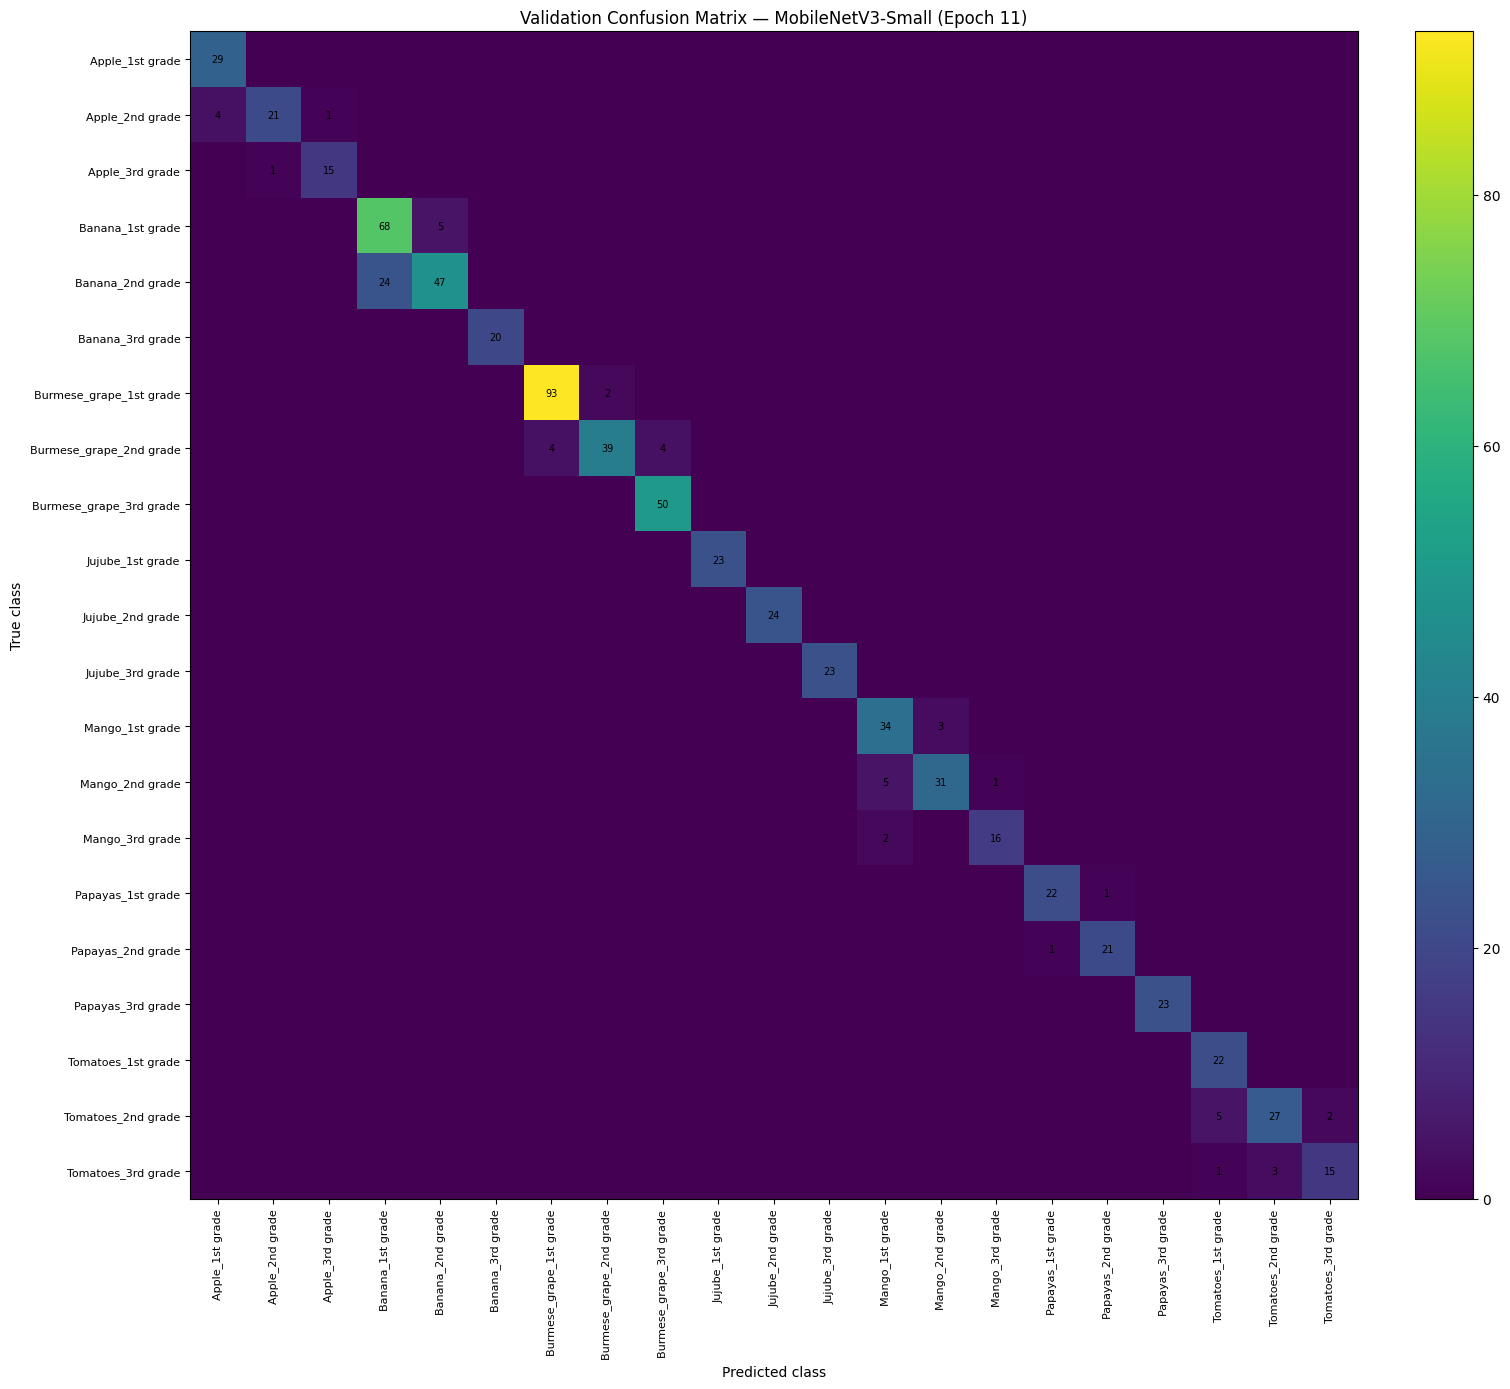

VALIDATION CLASS-WISE ANALYSIS COMPLETE
Accuracy       : 0.905738
Macro Precision: 0.924336
Macro Recall   : 0.918462
Macro F1      : 0.918123
Weighted F1    : 0.904345
Correct       : 663
Incorrect     : 69

CLASS-WISE METRICS:
                         precision  recall  f1-score  support
Apple_1st grade             0.8788  1.0000    0.9355     29.0
Apple_2nd grade             0.9545  0.8077    0.8750     26.0
Apple_3rd grade             0.9375  0.9375    0.9375     16.0
Banana_1st grade            0.7391  0.9315    0.8242     73.0
Banana_2nd grade            0.9038  0.6620    0.7642     71.0
Banana_3rd grade            1.0000  1.0000    1.0000     20.0
Burmese_grape_1st grade     0.9588  0.9789    0.9688     95.0
Burmese_grape_2nd grade     0.9512  0.8298    0.8864     47.0
Burmese_grape_3rd grade     0.9259  1.0000    0.9615     50.0
Jujube_1st grade            1.0000  1.0000    1.0000     23.0
Jujube_2nd grade            1.0000  1.0000    1.0000     24.0
Jujube_3rd grade           

In [38]:
# STEP 6 — Validation class-wise metrics and confusion matrix
# Validation-only. No model training. Test split remains sealed.

from pathlib import Path
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

PROJECT_ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
EXP_DIR = PROJECT_ROOT / "experiments" / "baseline_mobilenetv3_small"
ANALYSIS_DIR = EXP_DIR / "validation_analysis"

PRED_PATH = ANALYSIS_DIR / "validation_predictions_epoch11.csv"
CLASS_MAP_PATH = EXP_DIR / "class_to_index.json"

ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PRED_PATH)

with open(CLASS_MAP_PATH, "r") as f:
    class_to_index = json.load(f)

# Use the frozen class ordering
class_names = [
    name for name, idx in sorted(
        class_to_index.items(), key=lambda item: item[1]
    )
]

y_true = df["class_name"].to_numpy()
y_pred = df["predicted_class"].to_numpy()

# Metrics
report = classification_report(
    y_true,
    y_pred,
    labels=class_names,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T
class_metrics_df = report_df.loc[class_names].copy()

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_names
)

accuracy = accuracy_score(y_true, y_pred)
macro_precision = precision_score(
    y_true, y_pred, labels=class_names,
    average="macro", zero_division=0
)
macro_recall = recall_score(
    y_true, y_pred, labels=class_names,
    average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_true, y_pred, labels=class_names,
    average="macro", zero_division=0
)
weighted_f1 = f1_score(
    y_true, y_pred, labels=class_names,
    average="weighted", zero_division=0
)

# Save class-wise metrics
class_metrics_path = ANALYSIS_DIR / "validation_class_metrics_epoch11.csv"
class_metrics_df.to_csv(class_metrics_path)

# Save full classification report (includes macro/weighted averages)
full_report_path = ANALYSIS_DIR / "validation_classification_report_epoch11.csv"
report_df.to_csv(full_report_path)

# Save confusion matrix CSV
cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_path = ANALYSIS_DIR / "validation_confusion_matrix_epoch11.csv"
cm_df.to_csv(cm_path)

# Save overall summary metrics
summary = {
    "split": "validation",
    "checkpoint_epoch": 11,
    "n_samples": int(len(df)),
    "n_classes": int(len(class_names)),
    "accuracy": float(accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "correct": int((y_true == y_pred).sum()),
    "incorrect": int((y_true != y_pred).sum()),
    "test_split_accessed": False
}

summary_path = ANALYSIS_DIR / "validation_summary_epoch11.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(16, 14))

im = ax.imshow(cm, interpolation="nearest")
ax.set_title("Validation Confusion Matrix — MobileNetV3-Small (Epoch 11)")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")

ax.set_xticks(np.arange(len(class_names)))
ax.set_yticks(np.arange(len(class_names)))
ax.set_xticklabels(class_names, rotation=90, fontsize=8)
ax.set_yticklabels(class_names, fontsize=8)

# Annotate counts
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if cm[i, j] != 0:
            ax.text(j, i, str(cm[i, j]),
                    ha="center", va="center", fontsize=7)

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()

cm_plot_path = ANALYSIS_DIR / "validation_confusion_matrix_epoch11.png"
fig.savefig(cm_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Print summary
print("=" * 75)
print("VALIDATION CLASS-WISE ANALYSIS COMPLETE")
print("=" * 75)
print(f"Accuracy       : {accuracy:.6f}")
print(f"Macro Precision: {macro_precision:.6f}")
print(f"Macro Recall   : {macro_recall:.6f}")
print(f"Macro F1      : {macro_f1:.6f}")
print(f"Weighted F1    : {weighted_f1:.6f}")
print(f"Correct       : {(y_true == y_pred).sum()}")
print(f"Incorrect     : {(y_true != y_pred).sum()}")

print("\nCLASS-WISE METRICS:")
print(class_metrics_df[["precision", "recall", "f1-score", "support"]].round(4))

print("\nSAVED FILES:")
print(class_metrics_path)
print(full_report_path)
print(cm_path)
print(summary_path)
print(cm_plot_path)

print("\nTest split accessed: NO")
print("=" * 75)

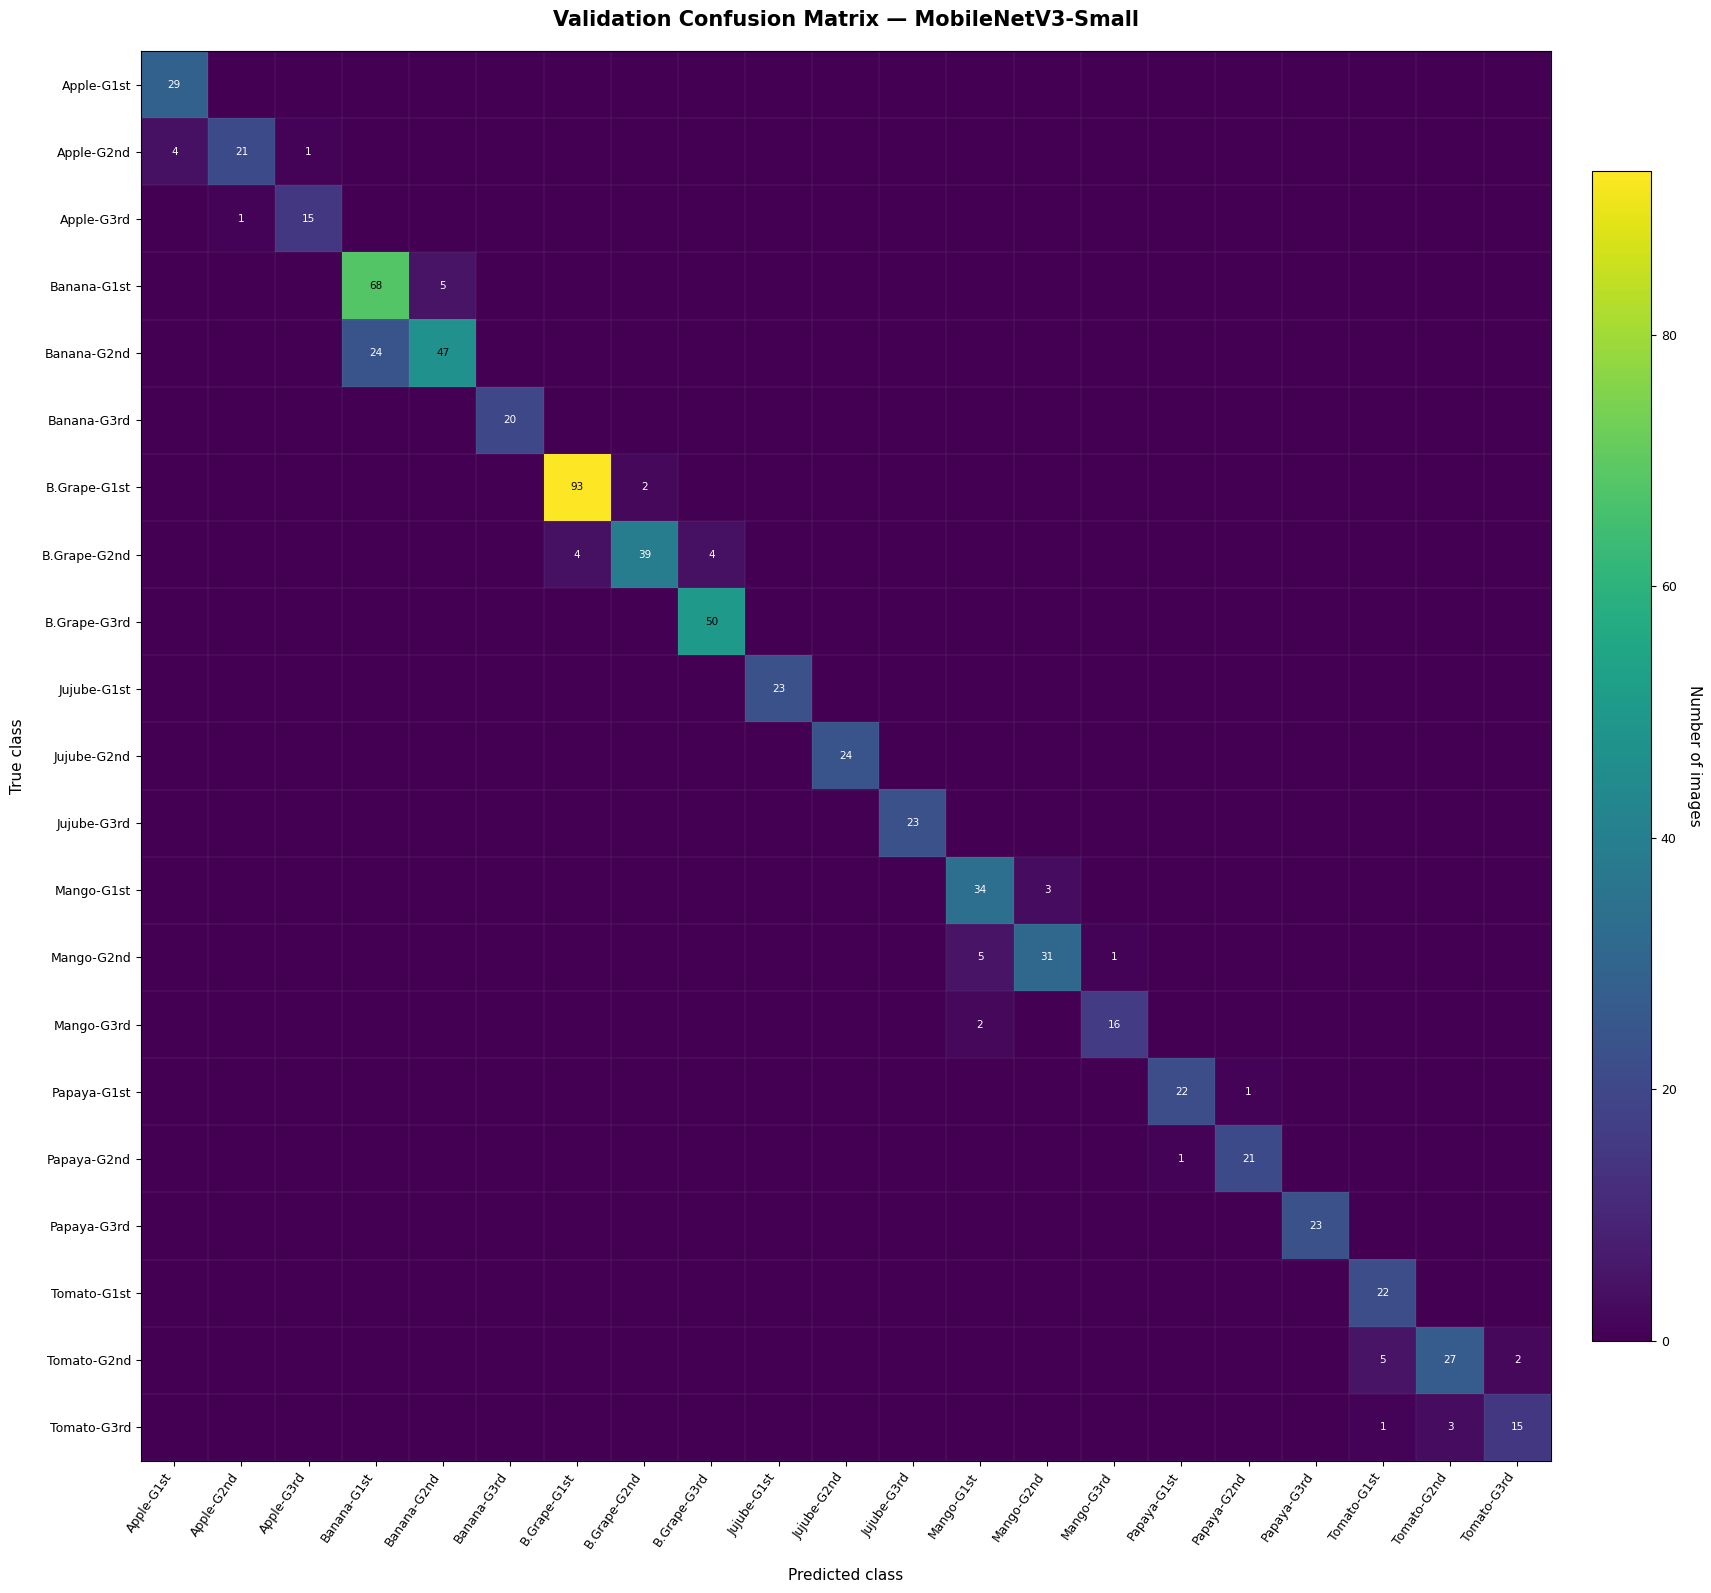

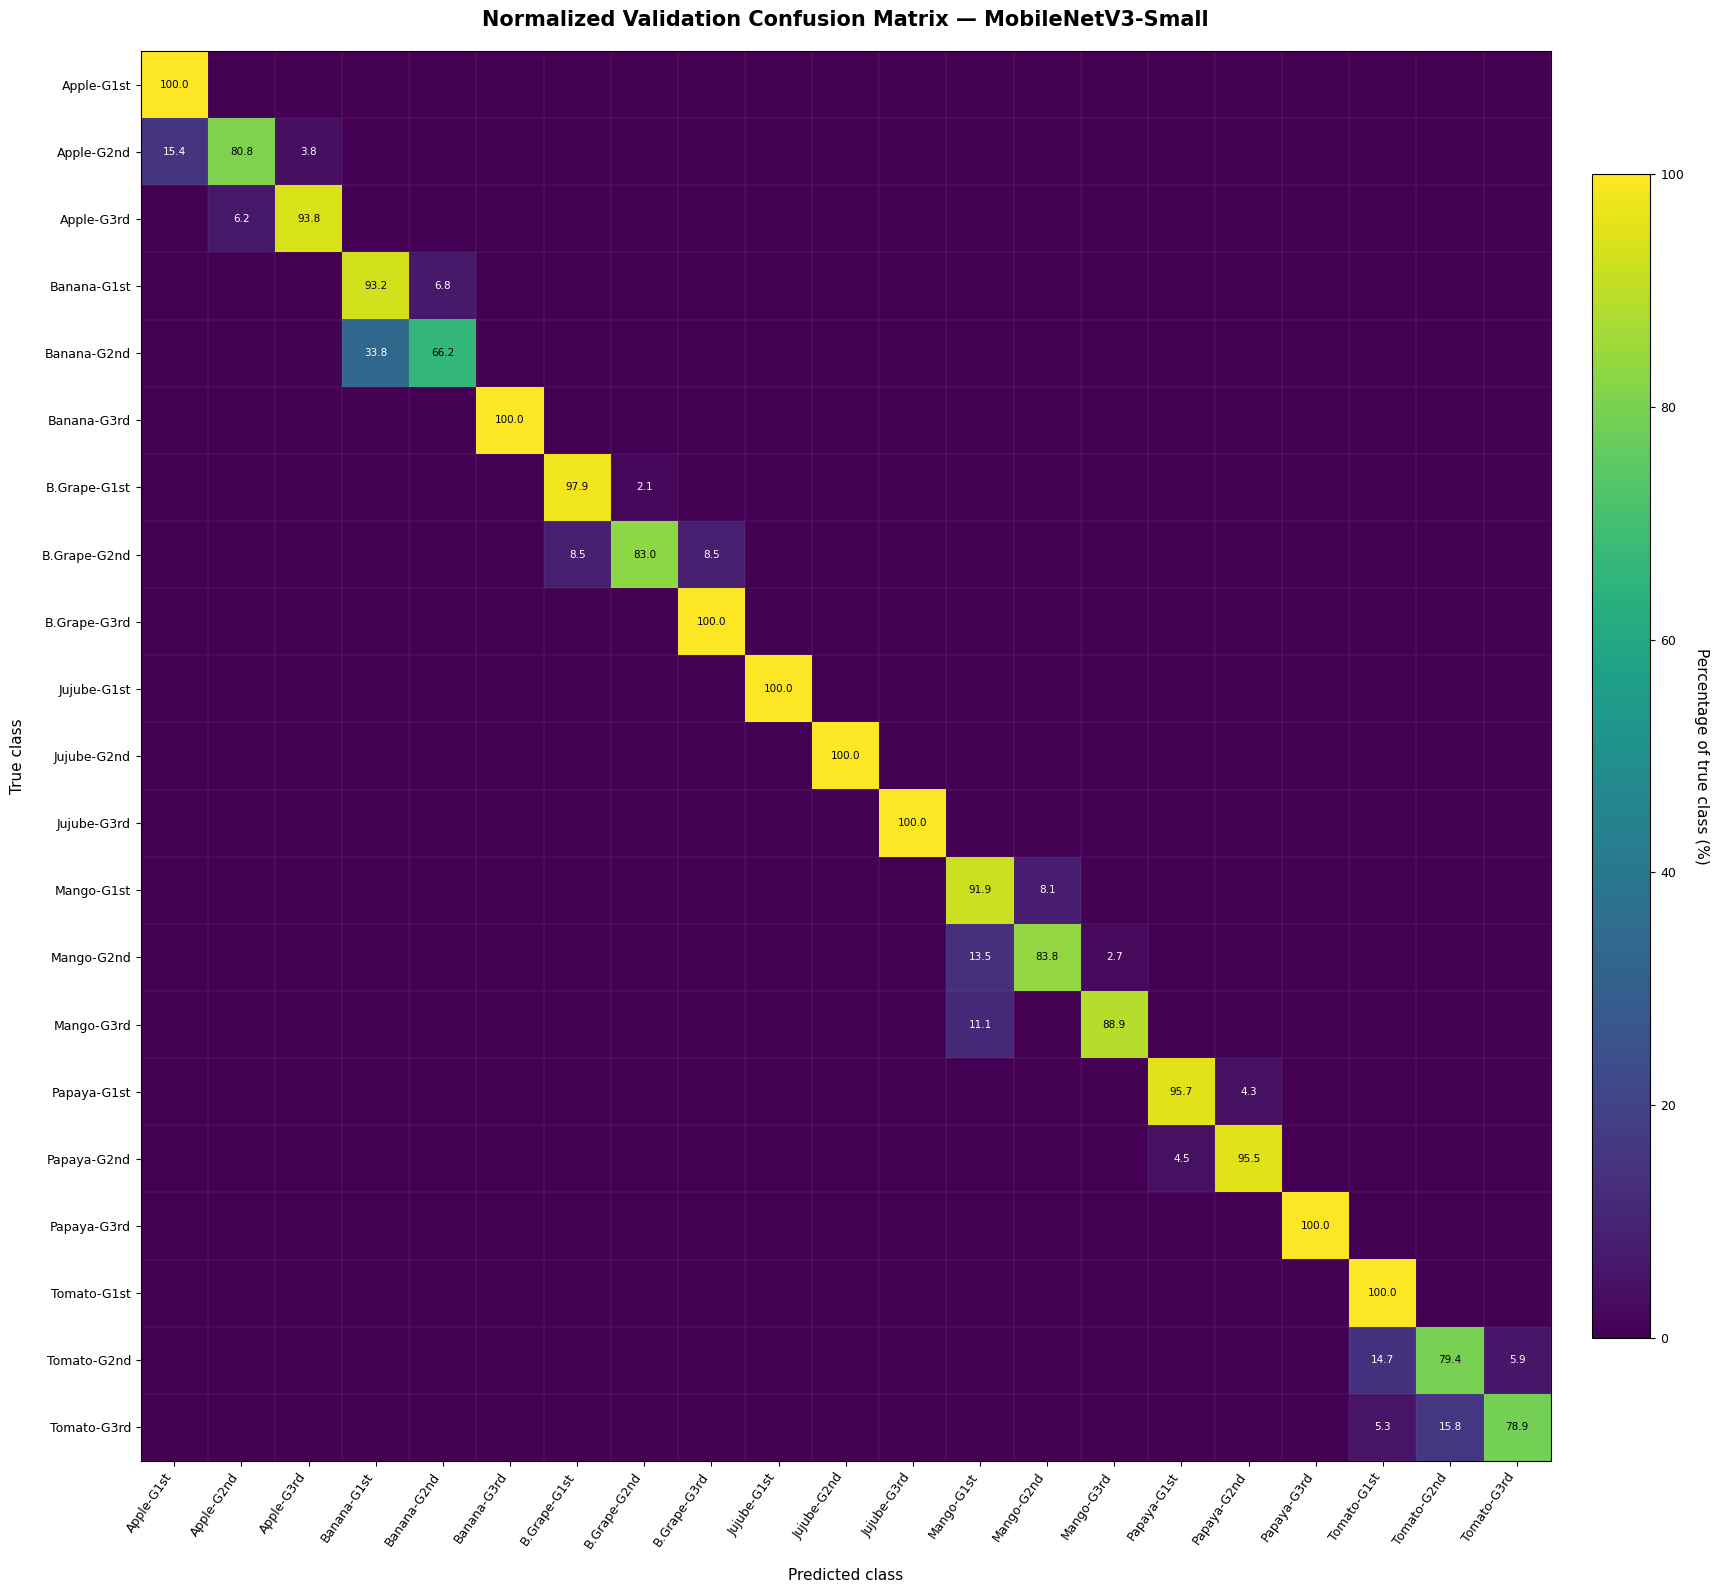

PUBLICATION FIGURES CREATED
Output folder: /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/validation_analysis/publication_figures

Files:
confusion_matrix_counts_epoch11.pdf | 36.1 KB
confusion_matrix_counts_epoch11.png | 1466.2 KB
confusion_matrix_label_key.csv | 0.7 KB
confusion_matrix_normalized_epoch11.pdf | 37.3 KB
confusion_matrix_normalized_epoch11.png | 1581.7 KB

Original confusion matrix preserved.
Training: NOT performed
Test split: NOT accessed


In [39]:
# STEP 7 — Create publication-quality confusion matrices
# Visualization only. No training, inference, or test-set access.

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
EXP_DIR = PROJECT_ROOT / "experiments" / "baseline_mobilenetv3_small"
ANALYSIS_DIR = EXP_DIR / "validation_analysis"

CM_PATH = ANALYSIS_DIR / "validation_confusion_matrix_epoch11.csv"

# Publication figure output directory
PUB_DIR = ANALYSIS_DIR / "publication_figures"
PUB_DIR.mkdir(parents=True, exist_ok=True)

# Load existing confusion matrix (do not alter the original)
cm_df = pd.read_csv(CM_PATH, index_col=0)
cm = cm_df.to_numpy(dtype=int)
class_names = list(cm_df.index)

assert cm.shape == (21, 21), f"Unexpected matrix shape: {cm.shape}"
assert cm.sum() == 732, f"Unexpected total: {cm.sum()}"

# Short labels for plot readability
def abbreviate_class(name):
    fruit, grade = name.rsplit("_", 1)
    grade_num = grade.replace("grade", "").strip()
    fruit_short = {
        "Apple": "Apple",
        "Banana": "Banana",
        "Burmese_grape": "B.Grape",
        "Jujube": "Jujube",
        "Mango": "Mango",
        "Papayas": "Papaya",
        "Tomatoes": "Tomato",
    }.get(fruit, fruit)
    return f"{fruit_short}-G{grade_num}"

short_labels = [abbreviate_class(c) for c in class_names]

# Save label key for reproducibility
label_key = pd.DataFrame({
    "original_class_name": class_names,
    "plot_label": short_labels,
    "class_index": range(21)
})
label_key.to_csv(PUB_DIR / "confusion_matrix_label_key.csv", index=False)

# Row-normalized matrix: each true class row sums to 100%
row_totals = cm.sum(axis=1, keepdims=True)
cm_percent = np.divide(
    cm * 100.0,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

# Shared plotting settings
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 15,
    "axes.labelsize": 11,
})

def plot_matrix(matrix, title, colorbar_label, annotation_format,
                output_stem, vmax=None):

    # Large canvas suitable for a manuscript page
    fig, ax = plt.subplots(figsize=(18, 16))

    im = ax.imshow(
        matrix,
        interpolation="nearest",
        aspect="equal",
        vmax=vmax
    )

    ax.set_title(title, pad=18, fontweight="bold")
    ax.set_xlabel("Predicted class", labelpad=12)
    ax.set_ylabel("True class", labelpad=12)

    ax.set_xticks(np.arange(21))
    ax.set_yticks(np.arange(21))

    ax.set_xticklabels(short_labels, rotation=55, ha="right", fontsize=9)
    ax.set_yticklabels(short_labels, fontsize=9)

    # Show nonzero cells only to avoid unnecessary visual clutter
    threshold = matrix.max() * 0.45

    for i in range(21):
        for j in range(21):
            value = matrix[i, j]

            if value > 0:
                text_value = annotation_format(value)

                text_color = (
                    "white" if value < threshold else "black"
                )

                ax.text(
                    j, i, text_value,
                    ha="center",
                    va="center",
                    fontsize=7.5,
                    color=text_color
                )

    # Thin grid separating cells
    ax.set_xticks(np.arange(-0.5, 21, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 21, 1), minor=True)
    ax.grid(which="minor", linestyle="-", linewidth=0.25, alpha=0.35)
    ax.tick_params(which="minor", bottom=False, left=False)

    cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.025)
    cbar.set_label(colorbar_label, rotation=270, labelpad=18)

    fig.tight_layout()

    # Vector PDF (sharp at any zoom)
    fig.savefig(
        PUB_DIR / f"{output_stem}.pdf",
        bbox_inches="tight"
    )

    # High-resolution raster
    fig.savefig(
        PUB_DIR / f"{output_stem}.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# Figure 1: raw counts
plot_matrix(
    matrix=cm,
    title="Validation Confusion Matrix — MobileNetV3-Small",
    colorbar_label="Number of images",
    annotation_format=lambda x: f"{int(x)}",
    output_stem="confusion_matrix_counts_epoch11"
)

# Figure 2: row-normalized percentages
plot_matrix(
    matrix=cm_percent,
    title="Normalized Validation Confusion Matrix — MobileNetV3-Small",
    colorbar_label="Percentage of true class (%)",
    annotation_format=lambda x: f"{x:.1f}",
    output_stem="confusion_matrix_normalized_epoch11",
    vmax=100
)

print("=" * 70)
print("PUBLICATION FIGURES CREATED")
print("=" * 70)
print("Output folder:", PUB_DIR)
print("\nFiles:")
for f in sorted(PUB_DIR.iterdir()):
    print(f"{f.name} | {f.stat().st_size / 1024:.1f} KB")

print("\nOriginal confusion matrix preserved.")
print("Training: NOT performed")
print("Test split: NOT accessed")

In [40]:
# STEP 8 — Ranked validation confusion pairs
# Read-only analysis of the existing confusion matrix.

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
EXP_DIR = PROJECT_ROOT / "experiments" / "baseline_mobilenetv3_small"
ANALYSIS_DIR = EXP_DIR / "validation_analysis"

CM_PATH = ANALYSIS_DIR / "validation_confusion_matrix_epoch11.csv"

cm_df = pd.read_csv(CM_PATH, index_col=0)
cm = cm_df.to_numpy(dtype=int)
class_names = list(cm_df.index)

assert cm.shape == (21, 21)
assert cm.sum() == 732

rows = []

for i, true_class in enumerate(class_names):
    support = int(cm[i, :].sum())

    for j, predicted_class in enumerate(class_names):
        if i == j:
            continue

        errors = int(cm[i, j])

        if errors > 0:
            rows.append({
                "true_class": true_class,
                "predicted_class": predicted_class,
                "misclassified_images": errors,
                "true_class_support": support,
                "percentage_of_true_class": (
                    errors / support * 100 if support else 0
                )
            })

error_pairs = pd.DataFrame(rows)

error_pairs = error_pairs.sort_values(
    ["misclassified_images", "percentage_of_true_class"],
    ascending=False
).reset_index(drop=True)

output_path = ANALYSIS_DIR / "ranked_validation_confusion_pairs_epoch11.csv"
error_pairs.to_csv(output_path, index=False)

print("=" * 75)
print("RANKED VALIDATION CONFUSION PAIRS")
print("=" * 75)

print(error_pairs.to_string(
    index=False,
    formatters={
        "percentage_of_true_class": lambda x: f"{x:.2f}%"
    }
))

print("\nTotal off-diagonal errors:", int(error_pairs["misclassified_images"].sum()))
print("Total incorrect predictions: 69")
print("\nSaved:", output_path)
print("Test split accessed: NO")
print("=" * 75)

RANKED VALIDATION CONFUSION PAIRS
             true_class         predicted_class  misclassified_images  true_class_support percentage_of_true_class
       Banana_2nd grade        Banana_1st grade                    24                  71                   33.80%
     Tomatoes_2nd grade      Tomatoes_1st grade                     5                  34                   14.71%
        Mango_2nd grade         Mango_1st grade                     5                  37                   13.51%
       Banana_1st grade        Banana_2nd grade                     5                  73                    6.85%
        Apple_2nd grade         Apple_1st grade                     4                  26                   15.38%
Burmese_grape_2nd grade Burmese_grape_1st grade                     4                  47                    8.51%
Burmese_grape_2nd grade Burmese_grape_3rd grade                     4                  47                    8.51%
     Tomatoes_3rd grade      Tomatoes_2nd grad

In [41]:
# STEP 9 — Deterministic, class-balanced XAI sample selection
# Validation split ONLY. No training and no test access.

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
EXP_DIR = PROJECT_ROOT / "experiments" / "baseline_mobilenetv3_small"
ANALYSIS_DIR = EXP_DIR / "validation_analysis"

PRED_PATH = ANALYSIS_DIR / "validation_predictions_epoch11.csv"

df = pd.read_csv(PRED_PATH)

assert len(df) == 732
assert df["sha256"].nunique() == 732
assert df["split"].eq("validation").all()

selected = []

# Frozen class order from the validation data
class_names = sorted(df["class_name"].unique())

for class_name in class_names:

    class_df = df[df["class_name"] == class_name].copy()

    # -----------------------------
    # 1. Representative correct case
    # -----------------------------
    correct_df = class_df[class_df["correct"] == True].copy()

    if len(correct_df) > 0:

        median_confidence = correct_df["confidence"].median()

        correct_df["distance_from_median"] = (
            correct_df["confidence"] - median_confidence
        ).abs()

        # Deterministic tie-breaking by SHA-256
        correct_df = correct_df.sort_values(
            ["distance_from_median", "sha256"],
            ascending=[True, True]
        )

        chosen_correct = correct_df.iloc[0].copy()

        selected.append({
            "selection_type": "representative_correct",
            "selection_rule": "Correct sample nearest class median confidence",
            "true_class": class_name,
            "predicted_class": chosen_correct["predicted_class"],
            "confidence": chosen_correct["confidence"],
            "correct": True,
            "sha256": chosen_correct["sha256"],
            "filename": chosen_correct.get("filename", ""),
            "relative_path": chosen_correct.get("relative_path", ""),
            "cache_path": chosen_correct.get("cache_path_persistent",
                                        chosen_correct.get("cache_path", ""))
        })

    # -----------------------------
    # 2. High-confidence failure
    # -----------------------------
    error_df = class_df[class_df["correct"] == False].copy()

    if len(error_df) > 0:

        error_df = error_df.sort_values(
            ["confidence", "sha256"],
            ascending=[False, True]
        )

        chosen_error = error_df.iloc[0].copy()

        selected.append({
            "selection_type": "high_confidence_error",
            "selection_rule": "Highest-confidence incorrect prediction within true class",
            "true_class": class_name,
            "predicted_class": chosen_error["predicted_class"],
            "confidence": chosen_error["confidence"],
            "correct": False,
            "sha256": chosen_error["sha256"],
            "filename": chosen_error.get("filename", ""),
            "relative_path": chosen_error.get("relative_path", ""),
            "cache_path": chosen_error.get("cache_path_persistent",
                                        chosen_error.get("cache_path", ""))
        })

selection_df = pd.DataFrame(selected)

# Ensure no duplicate image selected
assert selection_df["sha256"].nunique() == len(selection_df)

# Summary by class
selection_summary = (
    selection_df.groupby(["true_class", "selection_type"])
    .size()
    .unstack(fill_value=0)
)

# Save results
selection_path = ANALYSIS_DIR / "predefined_xai_selection_epoch11.csv"
summary_path = ANALYSIS_DIR / "predefined_xai_selection_summary_epoch11.csv"

selection_df.to_csv(selection_path, index=False)
selection_summary.to_csv(summary_path)

print("=" * 75)
print("PREDEFINED XAI SAMPLE SELECTION COMPLETE")
print("=" * 75)

print("Selected total samples:", len(selection_df))
print("Correct representative cases:",
      (selection_df["selection_type"] == "representative_correct").sum())
print("High-confidence failures:",
      (selection_df["selection_type"] == "high_confidence_error").sum())

print("\nSelection summary by class:")
print(selection_summary.to_string())

print("\nSelected failure cases:")
failures = selection_df[
    selection_df["selection_type"] == "high_confidence_error"
]

if len(failures):
    print(failures[
        ["true_class", "predicted_class", "confidence", "sha256"]
    ].to_string(index=False))

print("\nSaved:")
print(selection_path)
print(summary_path)

print("\nTraining performed: NO")
print("Test split accessed: NO")
print("=" * 75)

PREDEFINED XAI SAMPLE SELECTION COMPLETE
Selected total samples: 34
Correct representative cases: 21
High-confidence failures: 13

Selection summary by class:
selection_type           high_confidence_error  representative_correct
true_class                                                            
Apple_1st grade                              0                       1
Apple_2nd grade                              1                       1
Apple_3rd grade                              1                       1
Banana_1st grade                             1                       1
Banana_2nd grade                             1                       1
Banana_3rd grade                             0                       1
Burmese_grape_1st grade                      1                       1
Burmese_grape_2nd grade                      1                       1
Burmese_grape_3rd grade                      0                       1
Jujube_1st grade                             0              

XAI IMAGE VERIFICATION
Selected images: 34
Files existing: 34
Images readable: 34
Failures: 0

PASS | All predefined images exist and are readable


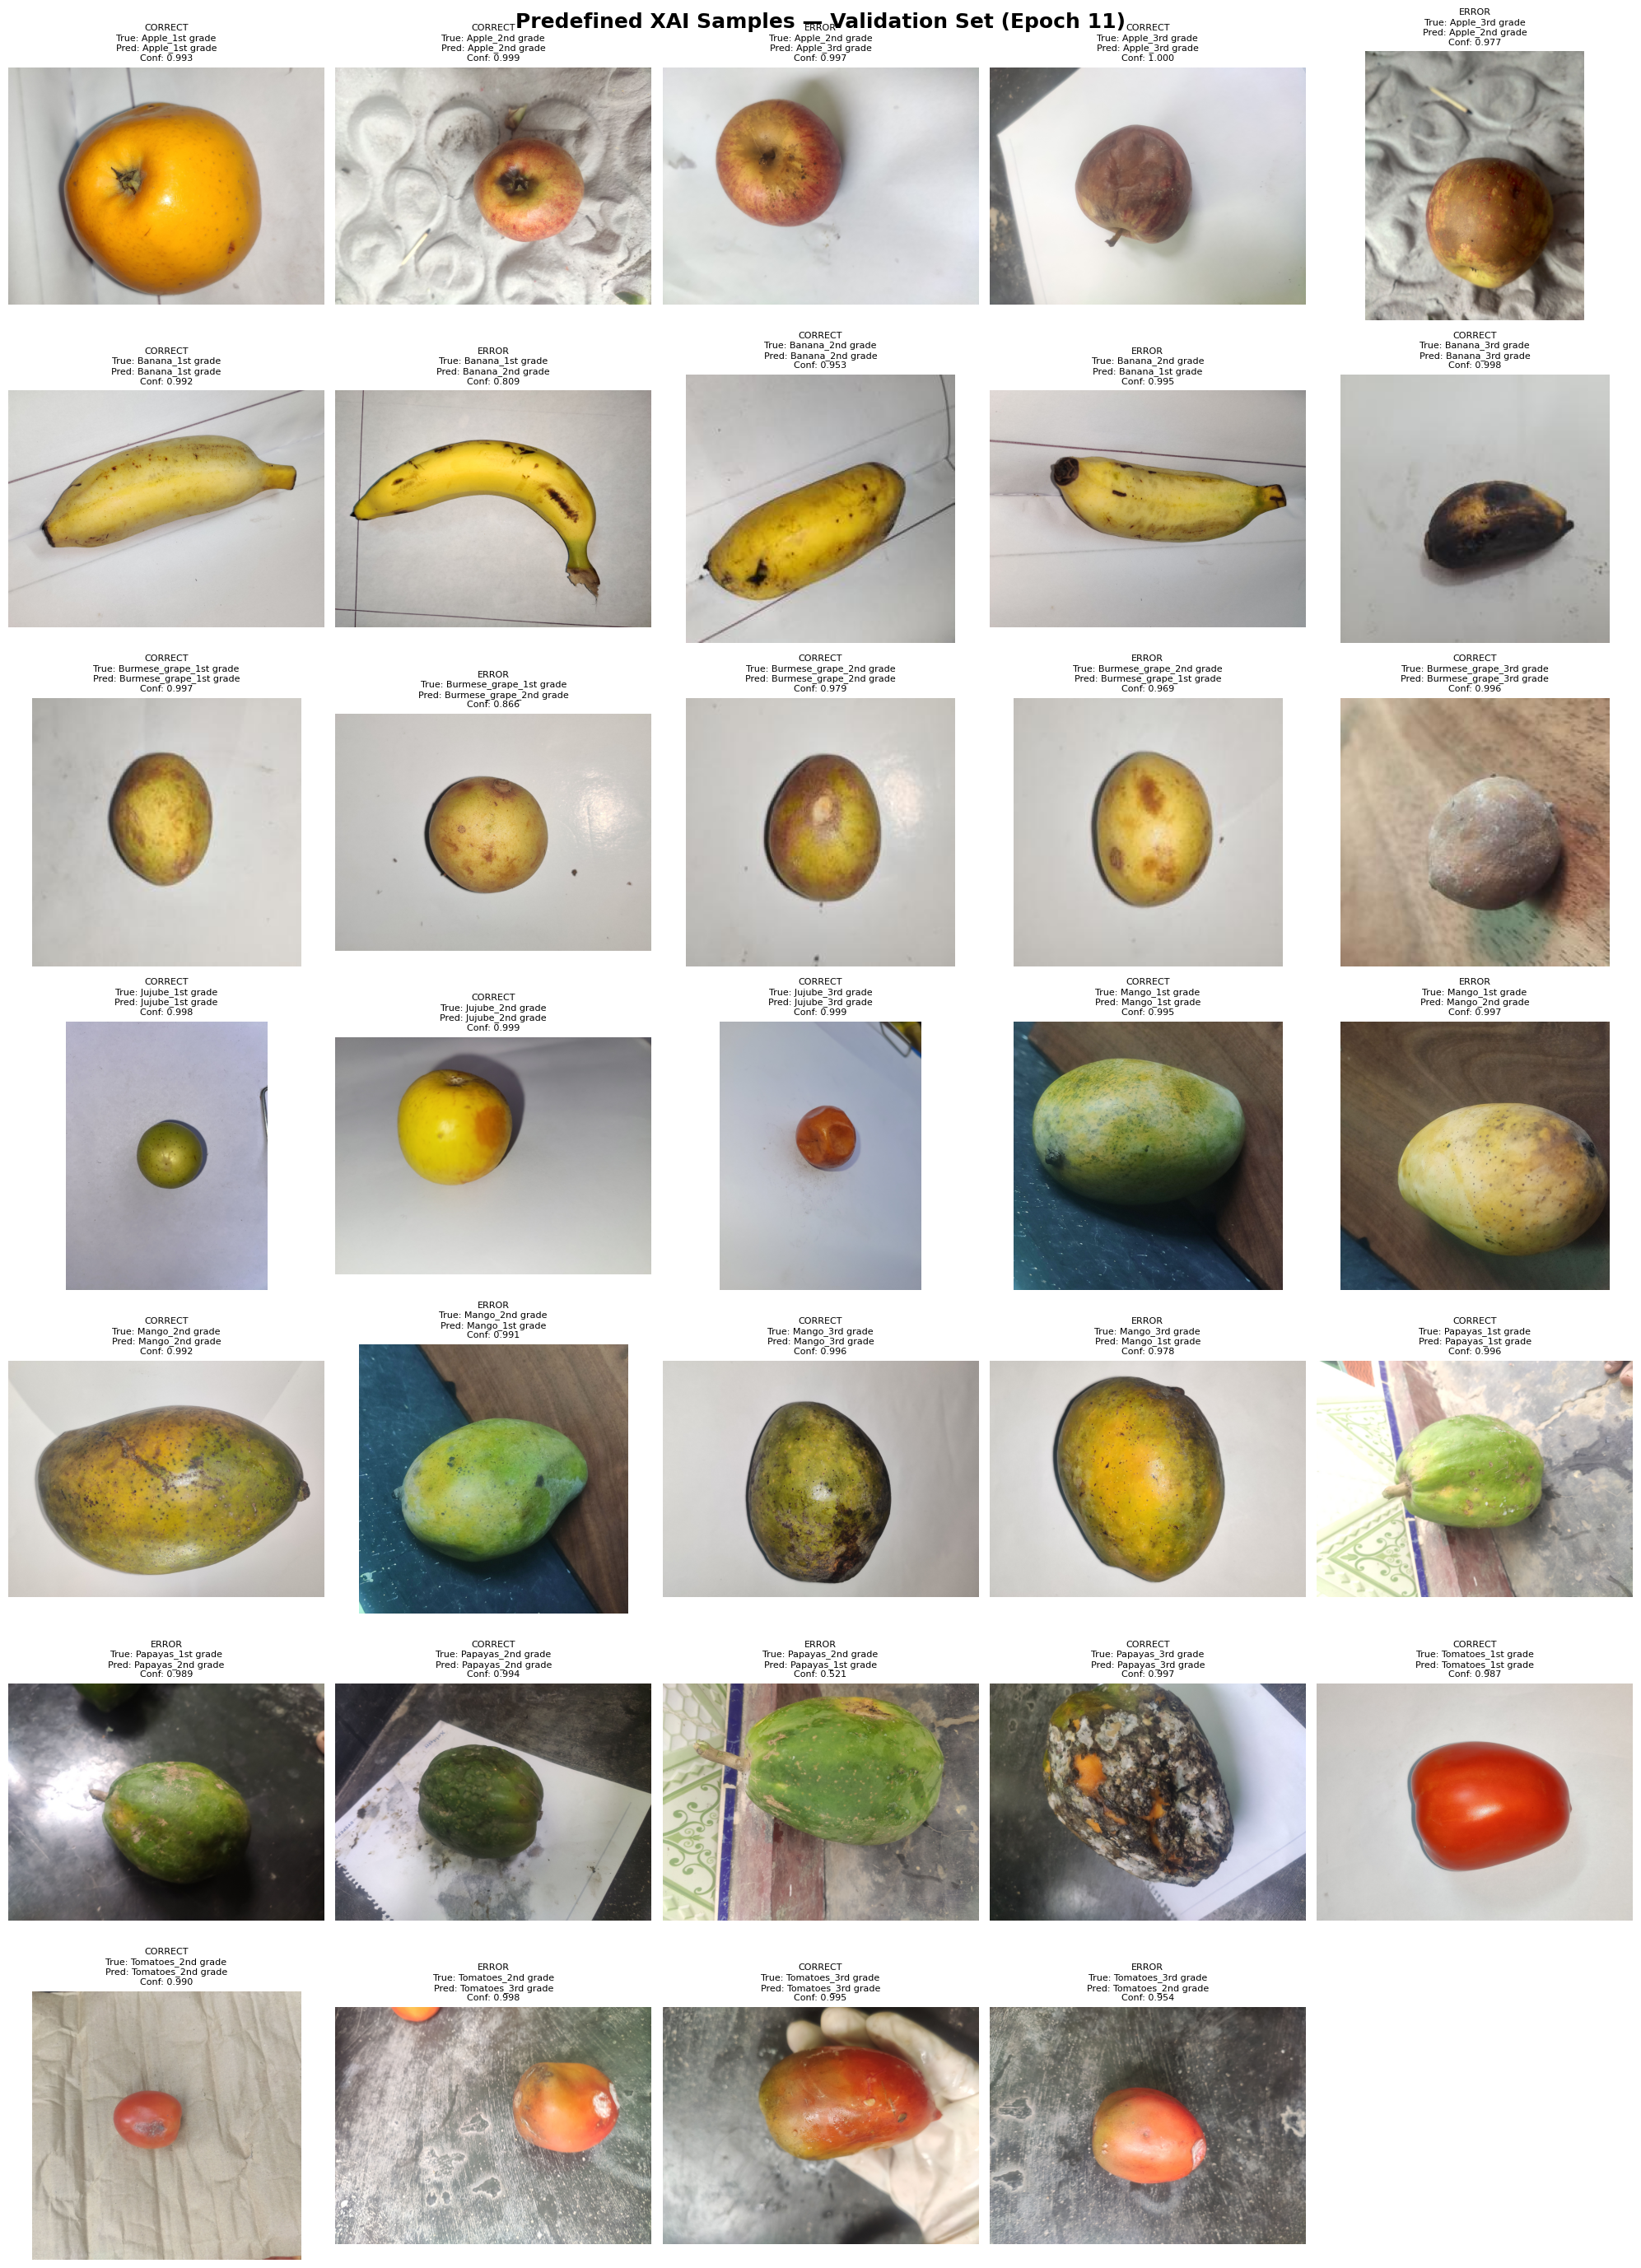


Contact sheet saved:
/content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/validation_analysis/xai_sample_contact_sheet_epoch11.png

Verification CSV saved:
/content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/validation_analysis/xai_sample_image_verification_epoch11.csv

Training performed: NO
Test split accessed: NO


In [42]:
# STEP 10 — Verify and visually inspect predefined XAI samples
# Image/path verification only. No training, no inference, no test access.

from pathlib import Path
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import math

PROJECT_ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
EXP_DIR = PROJECT_ROOT / "experiments" / "baseline_mobilenetv3_small"
ANALYSIS_DIR = EXP_DIR / "validation_analysis"

SELECTION_PATH = ANALYSIS_DIR / "predefined_xai_selection_epoch11.csv"

selection = pd.read_csv(SELECTION_PATH)

assert len(selection) == 34
assert selection["sha256"].nunique() == 34
assert selection["correct"].sum() == 21

# Prefer persistent cache path, fall back to cache_path
def resolve_image_path(row):
    p = row.get("cache_path", "")
    if pd.notna(p) and str(p).strip():
        return Path(str(p))
    return None

selection["resolved_path"] = selection.apply(resolve_image_path, axis=1)

# Verify paths and image readability
verification = []

for _, row in selection.iterrows():
    path = row["resolved_path"]

    exists = path is not None and path.exists()
    readable = False
    image_size = None

    if exists:
        try:
            with Image.open(path) as im:
                im.verify()
            with Image.open(path) as im:
                image_size = im.size
            readable = True
        except Exception:
            readable = False

    verification.append({
        "sha256": row["sha256"],
        "selection_type": row["selection_type"],
        "true_class": row["true_class"],
        "predicted_class": row["predicted_class"],
        "confidence": row["confidence"],
        "path_exists": exists,
        "image_readable": readable,
        "image_size": str(image_size),
        "path": str(path) if path else ""
    })

verification_df = pd.DataFrame(verification)

verification_path = ANALYSIS_DIR / "xai_sample_image_verification_epoch11.csv"
verification_df.to_csv(verification_path, index=False)

print("=" * 70)
print("XAI IMAGE VERIFICATION")
print("=" * 70)
print("Selected images:", len(selection))
print("Files existing:", verification_df["path_exists"].sum())
print("Images readable:", verification_df["image_readable"].sum())
print("Failures:", (~verification_df["image_readable"]).sum())

assert verification_df["path_exists"].all(), "One or more images are missing"
assert verification_df["image_readable"].all(), "One or more images are unreadable"

print("\nPASS | All predefined images exist and are readable")

# Contact sheet of all 34 images
n = len(selection)
cols = 5
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
axes = axes.flatten()

for ax, (_, row) in zip(axes, selection.iterrows()):
    path = row["resolved_path"]

    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        ax.imshow(im)

    is_correct = bool(row["correct"])
    tag = "CORRECT" if is_correct else "ERROR"

    ax.set_title(
        f"{tag}\nTrue: {row['true_class']}\n"
        f"Pred: {row['predicted_class']}\n"
        f"Conf: {row['confidence']:.3f}",
        fontsize=8
    )
    ax.axis("off")

for ax in axes[n:]:
    ax.axis("off")

fig.suptitle(
    "Predefined XAI Samples — Validation Set (Epoch 11)",
    fontsize=18,
    fontweight="bold"
)
fig.tight_layout()

contact_sheet_path = ANALYSIS_DIR / "xai_sample_contact_sheet_epoch11.png"
fig.savefig(contact_sheet_path, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nContact sheet saved:")
print(contact_sheet_path)
print("\nVerification CSV saved:")
print(verification_path)
print("\nTraining performed: NO")
print("Test split accessed: NO")
print("=" * 70)